# EDA de la estación 803 (nivel, Q. La Aguadita)

Periodo: 1 dic 2025 a 30 abr 2026, en hora local (UTC-5). Columnas: `nivel` (cm; según la guía P-GAA-SIATA-110 es la distancia del sensor al fondo menos la distancia a la lámina de agua, sin publicar la cota de ese fondo) y `calidad` (código de SIATA; su diccionario está en esa guía, aparte de la ficha de la estación). Este notebook cubre A1 a A6 del enunciado para esta estación.

Contexto que se usa: la lluvia de la pluviométrica 35 (a unos 240 m, promedio de los dos balancines) y la temperatura de la 367 (mismo sitio que la 35). Los CSV crudos no se tocan: todo sale de `siata.datos` y de `parte2/salidas/` (se generan con `python -m siata.pipeline` desde `parte2/`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import mannwhitneyu, spearmanr

from siata import datos as D

FIGURAS = Path.cwd().parent / "figuras"
PERIODO = "1 dic 2025 a 30 abr 2026"
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)

# Los 7 códigos se agrupan en 4 clases para colorear (paleta colorblind validada para 4) y cada clase tiene su marcador
GRUPO = {1: "1 o 2: confiable", 2: "1 o 2: confiable", 151: "151 o 251: dudoso", 251: "151 o 251: dudoso",
         1502: "1502 o 2502: pico", 2502: "1502 o 2502: pico", 1504: "1504: negativo"}
COLOR = dict(zip(dict.fromkeys(GRUPO.values()), ["#0173b2", "#de8f05", "#029e73", "#d55e00"]))
MARCA = dict(zip(COLOR, ["o", "s", "^", "v"]))
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]


def fechas(ax, hora=False):
    """Fechas del eje x en español (día y mes; con hora si se pide)."""
    def f(x, pos=None):
        t = mdates.num2date(x)
        return f"{t.day} {MESES[t.month - 1]}" + (f"\n{t:%H:%M}" if hora else "")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(f))


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"02_{nombre}.png", dpi=110, bbox_inches="tight")


def puntos_por_codigo(ax, x):
    """Dispersión del nivel minutal coloreada por grupo de código de calidad."""
    for g, color in COLOR.items():
        s = x[x["grupo"] == g]
        if len(s):
            ax.scatter(s.index, s["nivel"], s=4, color=color, marker=MARCA[g], label=f"{g} ({len(s)} min)", lw=0)

In [2]:
crudo = D.cargar("803")
d = D.regularizar(crudo, "803")  # malla minutal en hora local; los huecos quedan en NaN, nada se interpola
salida = pd.read_parquet(D.DIR_SALIDAS / "minutal_803.parquet")  # lo mismo más las banderas del control propio
assert salida.index.equals(d.index)

nivel = d["nivel"].round(1)  # resolución real 0,1 cm (ver A1)
cal = d["calidad"]
grupo = cal.map(GRUPO)
meseta = cal.isin([151, 251])
nivel_util = nivel.where(~meseta)  # sin las mesetas 151/251 (ver A5: son falla del sensor)

d35 = pd.read_parquet(D.DIR_SALIDAS / "minutal_35.parquet")
lluvia = d35[["p1", "p2"]].mean(axis=1)  # mm por minuto, promedio de los dos balancines de la 35
lluvia0 = lluvia.fillna(0)  # solo para sumas móviles; la 35 tiene 7 minutos con -999
lluvia_3h = lluvia0.rolling("3h").sum()  # mm en las 3 h que terminan en cada minuto
t367 = pd.read_parquet(D.DIR_SALIDAS / "minutal_367.parquet")["t"]
print(f"{len(crudo)} filas crudas, {len(d)} minutos esperados, {int(d['presente'].sum())} con registro")

217318 filas crudas, 217440 minutos esperados, 217318 con registro


## A1. Perfilamiento

Tipos, rangos, nulos, centinelas, duplicados, orden y regularidad del índice, y resolución del nivel.

In [3]:
perfil = pd.DataFrame({"tipo": crudo.dtypes.astype(str), "nulos": crudo.isna().sum(), "distintos": crudo.nunique(),
                       "minimo": [crudo[c].min() for c in crudo], "maximo": [crudo[c].max() for c in crudo]})
display(perfil)
paso = crudo["fecha_hora"].diff().dropna().dt.total_seconds().div(60).astype(int)
print("duplicados (codigo, fecha_hora):", crudo.duplicated(["codigo", "fecha_hora"]).sum())
print("índice ordenado:", crudo["fecha_hora"].is_monotonic_increasing)
print("marcas con segundos distintos de cero:", (crudo["fecha_hora"].dt.second != 0).sum())
print("centinela -999 en nivel:", (crudo["nivel"] == -999).sum(), "| NaN en nivel:", crudo["nivel"].isna().sum())
print("minutos esperados sin fila:", len(d) - len(crudo))
print("paso entre filas consecutivas (minutos) y cuántas veces:", paso.value_counts().sort_index().to_dict())
print(f"niveles negativos: {(crudo['nivel'] < 0).sum()} ({(crudo['nivel'] < 0).mean():.1%})")
print("códigos de calidad:", sorted(crudo["calidad"].unique()))

,tipo,nulos,distintos,minimo,maximo
codigo,int64,0,1,803,803
fecha_hora,datetime64[us],0,217318,2025-12-01 00:00:00,2026-04-30 23:59:00
nivel,float64,0,1017,-7.099976,344.299988
calidad,int64,0,7,1,2502


duplicados (codigo, fecha_hora): 0
índice ordenado: True
marcas con segundos distintos de cero: 0
centinela -999 en nivel: 0 | NaN en nivel: 0
minutos esperados sin fila: 122
paso entre filas consecutivas (minutos) y cuántas veces: {1: 217297, 2: 7, 3: 4, 4: 1, 5: 1, 6: 1, 8: 1, 9: 1, 11: 1, 14: 1, 23: 1, 36: 1}
niveles negativos: 11680 (5.4%)
códigos de calidad: [np.int64(1), np.int64(2), np.int64(151), np.int64(251), np.int64(1502), np.int64(1504), np.int64(2502)]


En lo formal el archivo está limpio: 217 318 filas, sin duplicados, ordenado, sin marcas fuera de minuto, sin NaN y sin -999. Faltan 122 minutos (A2); el salto más largo entre filas es de 36 minutos. El nivel va de -7,1 a 344,3 cm y 11 680 valores (5,4 %) son negativos. La columna calidad tiene 7 códigos: 1, 2, 151, 251, 1502, 1504 y 2502. Los problemas de esta estación están en el contenido.

### Resolución del nivel y artefacto float32

Los valores salen como 2.700012 o 5.900024. ¿Cuál es la resolución real y de dónde sale ese ruido en el sexto decimal?

In [4]:
v = crudo["nivel"].to_numpy()
decimal = np.round(v, 1)
residuo = np.abs(v - decimal)
print(f"residuo máximo frente al múltiplo de 0,1 cm más cercano: {residuo.max():.2e} cm")
print(f"valores que son exactamente un decimal: {(residuo == 0).mean():.1%}")
print("todos los valores son exactos en float32:", bool((v.astype(np.float32).astype(float) == v).all()))
print(f"float32 del decimal reproduce el {(decimal.astype(np.float32).astype(float) == v).mean():.1%} de los valores")
print("paso mínimo entre valores distintos ya redondeados:", round(np.diff(np.unique(decimal)).min(), 3), "cm")

# Hipótesis: nivel = cota - distancia, con la resta hecha en float32
cotas = [300, 500, 540, 600, 620, 640, 660, 700, 1000]
reproduce = [((np.float32(H) - (H - decimal).astype(np.float32)).astype(float) == v).mean() for H in cotas]
display(pd.DataFrame({"cota supuesta (cm)": cotas, "fracción reproducida exacta": np.round(reproduce, 5)}))
i = int(np.argmax(decimal == 2.7))
print("ejemplo: float32(600) - float32(597.3) =", float(np.float32(600) - np.float32(597.3)), "| valor crudo:", v[i])

residuo máximo frente al múltiplo de 0,1 cm más cercano: 2.44e-05 cm
valores que son exactamente un decimal: 20.2%
todos los valores son exactos en float32: True
float32 del decimal reproduce el 21.4% de los valores
paso mínimo entre valores distintos ya redondeados: 0.1 cm


,cota supuesta (cm),fracción reproducida exacta
0,300,0.60183
1,500,0.60642
2,540,0.99993
3,600,1.00000
4,620,1.00000
5,640,1.00000
6,660,0.99999
7,700,0.99653
8,1000,0.99038


ejemplo: float32(600) - float32(597.3) = 2.70001220703125 | valor crudo: 2.70001220703125


La resolución real es 0,1 cm: el residuo frente al decimal más cercano no pasa de 2,4e-05 cm y el paso mínimo entre valores distintos es 0,1 cm. Todos los valores son float32 exactos, pero solo el 21,4 % coincide con el float32 del decimal, así que no es un simple cambio de tipo.

Lo que sí reproduce el 100 % de los valores es suponer que el nivel se calcula como cota menos distancia, con la resta en float32, para una cota entera entre 620 y 640 cm (entre 540 y 660 cm se reproduce más del 99,99 %). Por ejemplo, float32(600) menos float32(597,3) da 2,70001220703125, igual al dato crudo. Inferido: el sensor mide la distancia desde arriba hasta el agua y el nivel depende de una cota configurada de unos 6 m. Eso es coherente con un cero de referencia que no está documentado y con los negativos. En adelante el nivel se redondea a 0,1 cm.

## A2. Completitud temporal

Además de los minutos sin registro, se cuentan los minutos que llegan pero con código 151 o 251: están presentes, pero no son utilizables (ver A5).

In [5]:
falta = ~d["presente"]
bloque = (falta != falta.shift()).cumsum()[falta]
huecos = (pd.Series(d.index[falta], index=d.index[falta]).groupby(bloque).agg(["first", "last", "size"])
          .set_axis(["inicio", "fin", "minutos"], axis=1).sort_values("minutos", ascending=False).reset_index(drop=True))
print(f"{falta.sum()} minutos sin registro en {len(huecos)} huecos; completitud {d['presente'].mean():.2%}")
print("duración de los huecos (min):", huecos["minutos"].describe()[["min", "50%", "mean", "max"]].round(1).to_dict())
huecos["dia_semana"] = huecos["inicio"].dt.day_of_week.map(dict(enumerate(DIAS)))
display(huecos)

mes = d.index.to_period("M")
por_mes = pd.DataFrame({"minutos": falta.groupby(mes).size(), "sin_registro": falta.groupby(mes).sum(),
                        "con_151_251": meseta.groupby(mes).sum()})
por_mes["completitud_%"] = 100 * (1 - por_mes["sin_registro"] / por_mes["minutos"])
por_mes["utilizable_%"] = 100 * (1 - (por_mes["sin_registro"] + por_mes["con_151_251"]) / por_mes["minutos"])
display(por_mes.round(2))
print(f"periodo: completitud {d['presente'].mean():.2%}, utilizable {(d['presente'] & ~meseta).mean():.2%}")
por_hora = pd.DataFrame({"sin_registro": falta.groupby(d.index.hour).sum(), "con_151_251": meseta.groupby(d.index.hour).sum()})
print("minutos sin registro entre las 11 y las 13 h:", int(por_hora.loc[11:13, "sin_registro"].sum()), "de", int(falta.sum()))

122 minutos sin registro en 20 huecos; completitud 99.94%
duración de los huecos (min): {'min': 1.0, '50%': 2.0, 'mean': 6.1, 'max': 35.0}


,inicio,fin,minutos,dia_semana
0,2026-03-14 18:10:00,2026-03-14 18:44:00,35,sáb
1,2026-03-02 11:59:00,2026-03-02 12:20:00,22,lun
2,2025-12-10 12:38:00,2025-12-10 12:50:00,13,mié
3,2026-04-14 12:29:00,2026-04-14 12:38:00,10,mar
4,2026-01-08 11:52:00,2026-01-08 11:59:00,8,jue
5,2025-12-10 13:16:00,2025-12-10 13:22:00,7,mié
6,2026-02-06 13:23:00,2026-02-06 13:27:00,5,vie
7,2025-12-04 14:20:00,2025-12-04 14:23:00,4,jue
8,2026-03-11 11:37:00,2026-03-11 11:39:00,3,mié
9,2025-12-04 14:38:00,2025-12-04 14:39:00,2,jue


,minutos,sin_registro,con_151_251,completitud_%,utilizable_%
fecha_hora,,,,,
2025-12,44640,29,3862,99.94,91.28
2026-01,44640,15,15,99.97,99.93
2026-02,40320,5,4,99.99,99.98
2026-03,44640,63,4388,99.86,90.03
2026-04,43200,10,80,99.98,99.79


periodo: completitud 99.94%, utilizable 96.10%
minutos sin registro entre las 11 y las 13 h: 76 de 122


¿Cuándo falta el dato y cuándo llega pero no sirve, por día y por hora del día?

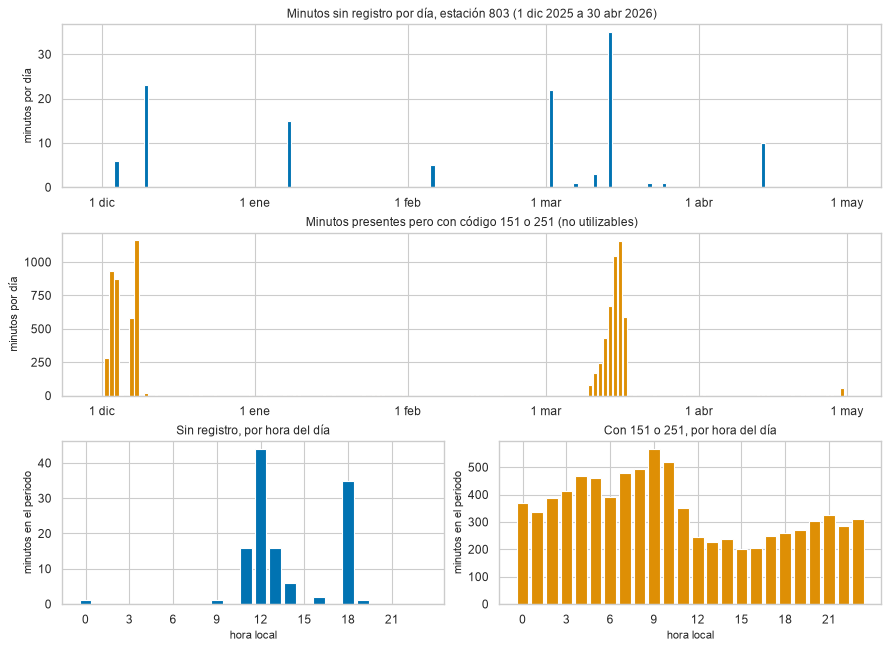

In [6]:
fig = plt.figure(figsize=(11, 8), constrained_layout=True)
gs = fig.add_gridspec(3, 2)
dia = pd.DataFrame({"sin_registro": falta.resample("D").sum(), "con_151_251": meseta.resample("D").sum()})
ax0 = fig.add_subplot(gs[0, :])
ax0.bar(dia.index, dia["sin_registro"], width=0.9, color=COLOR["1 o 2: confiable"])
ax0.set(ylabel="minutos por día", title=f"Minutos sin registro por día, estación 803 ({PERIODO})")
ax1 = fig.add_subplot(gs[1, :], sharex=ax0)
ax1.bar(dia.index, dia["con_151_251"], width=0.9, color=COLOR["151 o 251: dudoso"])
ax1.set(ylabel="minutos por día", title="Minutos presentes pero con código 151 o 251 (no utilizables)")
fechas(ax0); fechas(ax1)
for k, (col, titulo) in enumerate([("sin_registro", "Sin registro, por hora del día"),
                                    ("con_151_251", "Con 151 o 251, por hora del día")]):
    ax = fig.add_subplot(gs[2, k])
    ax.bar(por_hora.index, por_hora[col], color=COLOR["1 o 2: confiable" if k == 0 else "151 o 251: dudoso"])
    ax.set(xlabel="hora local", ylabel="minutos en el periodo", title=titulo, xticks=range(0, 24, 3))
plt.show()

La completitud es 99,94 %: 122 minutos en 20 huecos, con mediana de 2 minutos y el mayor de 35 (14 mar, 18:10 a 18:44). Los huecos no caen al azar: 76 de los 122 minutos están entre las 11 y las 13 h, y todos esos huecos son de días hábiles. Inferido: visitas de mantenimiento o reinicios en horario de trabajo; no hay bitácora para confirmarlo.

Lo que más reduce el dato útil son los 8349 minutos con 151/251. La fracción utilizable baja a 96,10 % en el periodo, a 91,28 % en diciembre y a 90,03 % en marzo. Esos minutos se concentran en la madrugada y la mañana, con el máximo a las 9 h.

¿Cómo se ven los huecos en la serie? Se dibuja el dato minutal tal cual: la línea se corta donde no hay registro (franjas grises) y no se interpola nada.

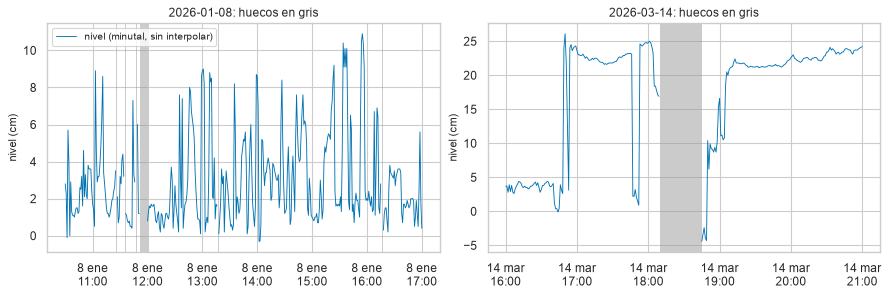

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for ax, (a, b) in zip(axs, [("2026-01-08 10:30", "2026-01-08 17:00"), ("2026-03-14 16:00", "2026-03-14 21:00")]):
    x = nivel.loc[a:b]
    ax.plot(x.index, x, lw=0.8, color=COLOR["1 o 2: confiable"], label="nivel (minutal, sin interpolar)")
    for h in huecos.itertuples():
        if h.fin >= pd.Timestamp(a) and h.inicio <= pd.Timestamp(b):
            ax.axvspan(h.inicio, h.fin + pd.Timedelta("1min"), color="0.6", alpha=0.5, lw=0)
    ax.set(ylabel="nivel (cm)", title=f"{a[:10]}: huecos en gris")
    fechas(ax, hora=True)
axs[0].legend(loc="upper left")
plt.show()

Los huecos quedan como cortes de la línea, sin rellenar. El 8 ene son cortes de 1 a 8 minutos dentro de una señal muy ruidosa, que salta entre 0 y 10 cm de un minuto a otro (ese ruido se cuantifica en A5). El 14 mar el hueco de 35 minutos cae dentro de la falla de marzo: antes y después la serie está en la meseta 151 de unos 22 cm (episodios en A5).

## A3. Distribución del nivel y de la columna calidad

El nivel es muy asimétrico: por eso se usan percentiles y conteos en escala logarítmica.

In [8]:
q = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
series = {"todos": nivel.dropna(), "sin 151/251": nivel_util.dropna(), "calidad 1": nivel[cal == 1]}
tabla = pd.DataFrame({k: s.quantile(q) for k, s in series.items()})
tabla.index = [f"p{100 * x:g}" for x in q]
tabla.loc["máximo"] = [s.max() for s in series.values()]
tabla.loc["media"] = [s.mean() for s in series.values()]
tabla.loc["asimetría"] = [s.skew() for s in series.values()]
tabla.loc["minutos"] = [len(s) for s in series.values()]
display(tabla.round(2))

,todos,sin 151/251,calidad 1
p0.1,-2.70,-2.80,-2.50
p1,-1.20,-1.20,-0.90
p5,-0.10,-0.10,0.10
p25,1.50,1.50,1.50
p50,2.70,2.60,2.60
p75,4.30,4.00,3.90
p95,11.00,7.60,6.60
p99,246.70,11.50,10.30
p99.9,334.10,14.20,13.70
máximo,344.30,36.20,36.20


¿Cómo se distribuye el nivel? A la izquierda, todos los datos separando los minutos 151/251; a la derecha, sin ellos. Conteos en escala logarítmica para ver las colas.

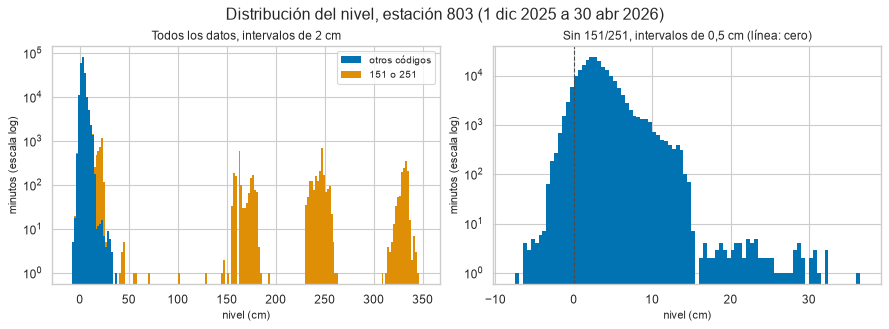

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
bins = np.arange(-10, 352, 2)
axs[0].hist([nivel[~meseta].dropna(), nivel[meseta]], bins=bins, stacked=True, log=True,
            color=[COLOR["1 o 2: confiable"], COLOR["151 o 251: dudoso"]], label=["otros códigos", "151 o 251"], edgecolor="none")
axs[0].set(xlabel="nivel (cm)", ylabel="minutos (escala log)", title="Todos los datos, intervalos de 2 cm")
axs[0].legend()
axs[1].hist(nivel_util.dropna(), bins=np.arange(-8, 37.5, 0.5), log=True, color=COLOR["1 o 2: confiable"], edgecolor="none")
axs[1].axvline(0, color="0.3", lw=1, ls="--")
axs[1].set(xlabel="nivel (cm)", ylabel="minutos (escala log)", title="Sin 151/251, intervalos de 0,5 cm (línea: cero)")
fig.suptitle(f"Distribución del nivel, estación 803 ({PERIODO})")
plt.show()

Hay dos poblaciones que no se mezclan. Sin 151/251 casi todo está entre -1,2 y 11,5 cm (p1 y p99), con mediana de 2,6 cm, y el máximo es 36,2 cm. Todo lo que pasa de 40 cm tiene código 151 o 251 y forma grupos en torno a 160, 245 y 330 cm. Por eso la media de todos los datos (8,73 cm) y su p99 (246,7 cm) no describen la quebrada: sin 151/251 la media es 3,01 cm y la asimetría baja de 6,92 a 1,46. A la izquierda la cola llega a -7,1 cm, por debajo del cero de referencia.

¿Cambia la distribución por mes y por hora del día? Sin 151/251; se muestran todos los puntos atípicos, no se recorta el eje.

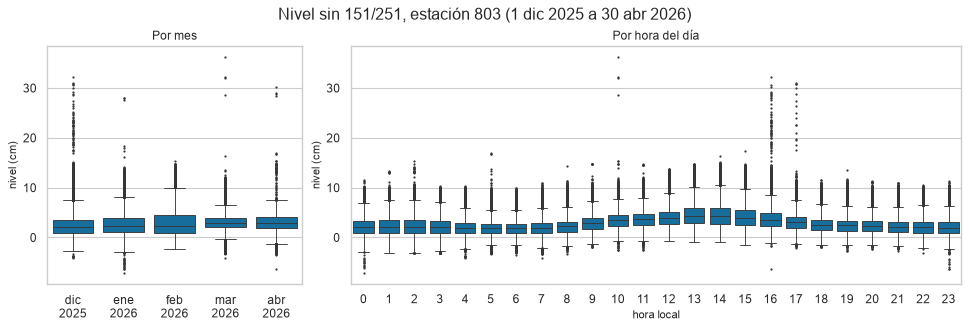

percentiles 25, 50 y 75 por mes (cm):
mes  dic 2025  ene 2026  feb 2026  mar 2026  abr 2026
25%       1.0       1.1       1.0       2.2       2.0
50%       2.2       2.3       2.4       3.0       3.0
75%       3.6       3.9       4.6       4.0       4.2


In [10]:
x = pd.DataFrame({"nivel": nivel_util, "mes": [f"{MESES[t.month - 1]}\n{t.year}" for t in nivel_util.index],
                  "hora": nivel_util.index.hour}).dropna()
fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True, gridspec_kw={"width_ratios": [1, 2.4]})
sns.boxplot(data=x, x="mes", y="nivel", ax=axs[0], color=COLOR["1 o 2: confiable"], fliersize=1, linewidth=0.8)
sns.boxplot(data=x, x="hora", y="nivel", ax=axs[1], color=COLOR["1 o 2: confiable"], fliersize=1, linewidth=0.8)
axs[0].set(xlabel="", ylabel="nivel (cm)", title="Por mes")
axs[1].set(xlabel="hora local", ylabel="nivel (cm)", title="Por hora del día")
fig.suptitle(f"Nivel sin 151/251, estación 803 ({PERIODO})")
plt.show()
print("percentiles 25, 50 y 75 por mes (cm):")
print(x.groupby("mes", sort=False)["nivel"].describe()[["25%", "50%", "75%"]].round(1).T.rename(columns=lambda c: c.replace(chr(10), " ")).to_string())

Por mes, la mediana pasa de 2,2 a 2,4 cm (dic a feb) a 3,0 cm (mar y abr), y el percentil 25 de 1,0 a 1,1 cm a 2,0 a 2,2 cm: es el cambio de línea base de marzo (A4). Por hora, el nivel es más alto entre las 10 y las 16 h, también en días secos (A4). Los atípicos de 20 a 36 cm aparecen sobre todo a las 10, 16 y 17 h, que coinciden con aguaceros.

### Columna calidad

Para cada código: cuántos minutos, qué niveles toma, cuánto se separa el dato de sus vecinos (desvío absoluto frente a la mediana móvil centrada de 11 minutos) y qué fracción tiene lluvia de al menos 1 mm en la 35 en las 3 h previas.

In [11]:
mediana_11 = nivel.rolling(11, center=True, min_periods=6).median()
t = pd.DataFrame({"cal": cal, "nivel": nivel, "desvio": (nivel - mediana_11).abs(), "con_lluvia": lluvia_3h >= 1})
g = t.dropna(subset=["cal"]).groupby("cal")
codigos = pd.DataFrame({"minutos": g.size(), "%": 100 * g.size() / cal.notna().sum(),
                        "nivel_p5": g["nivel"].quantile(0.05), "nivel_mediana": g["nivel"].median(),
                        "nivel_p95": g["nivel"].quantile(0.95), "desvio_mediano_cm": g["desvio"].median(),
                        "con_lluvia_3h_%": 100 * g["con_lluvia"].mean()})
codigos.index = codigos.index.astype(int)
display(codigos.round(2))
print("minutos por mes y código:")
display(pd.crosstab(mes[cal.notna()], cal.dropna().astype(int)))

,minutos,%,nivel_p5,nivel_mediana,nivel_p95,desvio_mediano_cm,con_lluvia_3h_%
cal,,,,,,,
1,191042,87.91,0.1,2.6,6.60,0.2,10.55
2,42,0.02,0.8,5.2,10.74,0.4,38.10
151,7955,3.66,17.3,164.9,333.10,0.1,2.33
251,394,0.18,155.8,157.7,158.90,0.0,0.25
1502,14333,6.60,-0.7,4.5,11.60,1.2,2.80
1504,2987,1.37,-2.0,-0.5,-0.10,0.3,3.38
2502,565,0.26,2.0,8.6,21.92,1.3,0.53


minutos por mes y código:


calidad,1,2,151,251,1502,1504,2502
row_0,,,,,,,
2025-12,35366,0,3468,394,1834,2987,562
2026-01,41422,10,15,0,3176,0,2
2026-02,36475,31,4,0,3804,0,1
2026-03,37723,1,4388,0,2465,0,0
2026-04,40056,0,80,0,3054,0,0


¿Qué valores toma el nivel en cada código? Eje en escala symlog: lineal entre -10 y 10 cm y logarítmico por fuera.

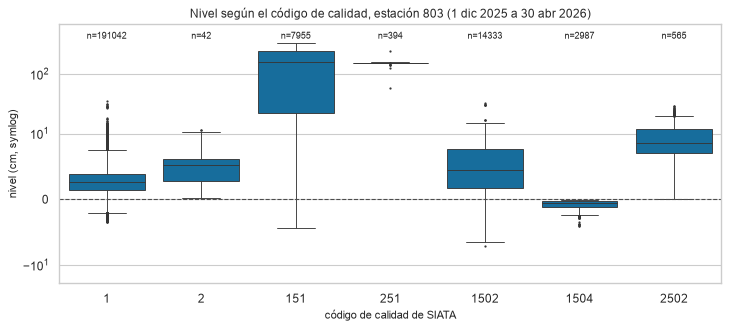

In [12]:
x = pd.DataFrame({"nivel": nivel, "codigo": cal}).dropna()
x["codigo"] = x["codigo"].astype(int).astype(str)
orden = [str(c) for c in sorted(codigos.index)]
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
sns.boxplot(data=x, x="codigo", y="nivel", order=orden, ax=ax, color=COLOR["1 o 2: confiable"], fliersize=1, linewidth=0.8)
ax.set_yscale("symlog", linthresh=10)
ax.axhline(0, color="0.3", lw=1, ls="--")
ax.set(xlabel="código de calidad de SIATA", ylabel="nivel (cm, symlog)", title=f"Nivel según el código de calidad, estación 803 ({PERIODO})")
for k, c in enumerate(orden):
    ax.text(k, 400, f"n={codigos.loc[int(c), 'minutos']}", ha="center", fontsize=8)
ax.set_ylim(-20, 700)
plt.show()

Cada código ocupa una franja de valores distinta, y eso permite inferir qué significa (inferido de los datos; el contraste con el diccionario oficial de la guía P-GAA-SIATA-110 está en el notebook 07):

- 1 (87,9 % de los minutos): nivel normal, mediana 2,6 cm.
- 151 (3,7 %) y 251 (0,2 %): mesetas, medianas de 164,9 y 157,7 cm; casi no se separan de sus vecinos (desvío de 0,1 y 0,0 cm), es decir, valor sostenido. Solo 2,3 % y 0,3 % tienen lluvia en las 3 h previas.
- 1502 (6,6 %): picos aislados; desvío mediano de 1,2 cm frente a 0,2 cm de los datos con 1, y solo 2,8 % con lluvia previa: son picos en tiempo seco.
- 1504 (1,4 %): siempre negativo (máximo -0,1 cm).
- 2502 (0,3 %): como 1502, con desvío de 1,3 cm, niveles algo más altos (p95 21,9 cm) y casi sin lluvia.
- 2 (42 minutos): valores normales.

Hipótesis sobre la estructura: el primer dígito indica la transmisión (1 en tiempo real, 2 no en tiempo real) y el resto la prueba que falló. La guía P-GAA-SIATA-110 (Tabla 2, p. 5) confirma el primer dígito, pero no el significado que aquí se infiere del resto: 151 es dudoso sin causa (el valor sostenido es 1500) y 1502 y 1504 tienen la misma descripción, oscilaciones fuera de rango. Lo de mesetas, picos y negativos sale de los datos.

¿Cómo cambian los códigos distintos de 1 a lo largo del periodo? Un panel por código, cada uno con su propia escala.

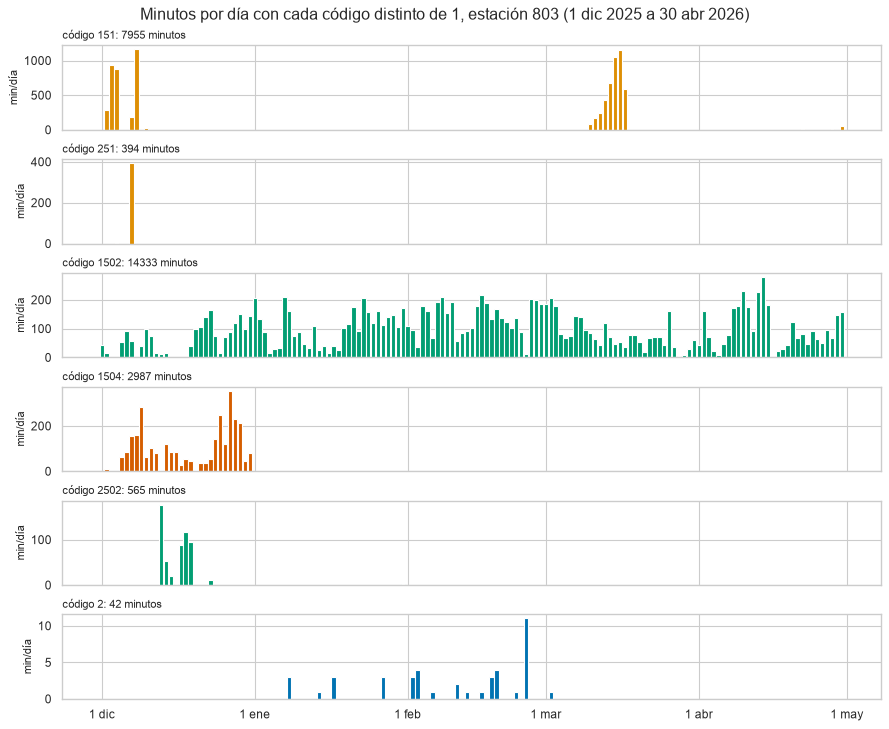

niveles negativos por mes y código:


calidad,1,151,1502,1504,total
row_0,,,,,
2025-12,0,1,0,2987,2988
2026-01,2241,3,326,0,2570
2026-02,2930,2,227,0,3159
2026-03,573,39,133,0,745
2026-04,1581,5,632,0,2218
total,7325,50,1318,2987,11680


¿todo 1504 es negativo? True | máximo con 1504: -0.1


In [13]:
otros = [151, 251, 1502, 1504, 2502, 2]
fig, axs = plt.subplots(len(otros), 1, figsize=(11, 9), sharex=True, constrained_layout=True)
for ax, c in zip(axs, otros):
    s = (cal == c).resample("D").sum()
    ax.bar(s.index, s, width=0.9, color=COLOR[GRUPO[c]])
    ax.set_ylabel("min/día")
    ax.set_title(f"código {c}: {int(s.sum())} minutos", loc="left", fontsize=10)
fechas(axs[-1])
fig.suptitle(f"Minutos por día con cada código distinto de 1, estación 803 ({PERIODO})")
plt.show()

neg = nivel < 0
print("niveles negativos por mes y código:")
display(pd.crosstab(mes[neg], cal[neg].astype(int), margins=True, margins_name="total"))
print("¿todo 1504 es negativo?", bool((nivel[cal == 1504] < 0).all()), "| máximo con 1504:", nivel[cal == 1504].max())

El algoritmo de calidad no fue el mismo en todo el periodo. En diciembre, de los 2988 negativos, 2987 llevan 1504; de enero a abril hay 7325 negativos con código 1 y ninguno con 1504. Los 394 minutos 251 y 562 de los 565 minutos 2502 son de diciembre. 1502 sí se mantiene (entre 1834 y 3804 minutos por mes). Así, un mismo valor, por ejemplo -1 cm, sale dudoso en diciembre y confiable en febrero. Cualquier estadística por código, o un modelo que use la columna calidad como etiqueta, hereda ese cambio.

## A4. Ciclos diurno y semanal, estacionalidad y tendencia

Día seco: menos de 0,5 mm en la 35 ese día y el anterior (así se evita la recesión de una lluvia previa).

In [14]:
lluvia_dia = lluvia0.resample("D").sum()
seco = (lluvia_dia < 0.5) & (lluvia_dia.shift(1) < 0.5)
dias_secos = seco[seco].index
en_seco = pd.Series(d.index.normalize().isin(dias_secos), index=d.index)
print("días secos:", len(dias_secos), "de", len(lluvia_dia))

hora = d.index.hour
perfil_todos = nivel_util.groupby(hora).median()
perfil_seco = nivel_util[en_seco].groupby(hora[en_seco.to_numpy()]).quantile([0.25, 0.5, 0.75]).unstack()
lluvia_hora = lluvia0.groupby(lluvia0.index.hour).sum()
t_seco = t367[en_seco.reindex(t367.index, fill_value=False)]
t_hora = t_seco.groupby(t_seco.index.hour).mean()
print("mediana por hora en días secos (cm):", perfil_seco[0.5].round(1).to_dict())
print(f"hora del mínimo {perfil_seco[0.5].idxmin()} h ({perfil_seco[0.5].min()} cm), "
      f"del máximo {perfil_seco[0.5].idxmax()} h ({perfil_seco[0.5].max()} cm)")
print(f"lluvia entre 14 y 16 h: {lluvia_hora.loc[14:16].sum():.0f} mm de {lluvia_hora.sum():.0f} mm")

días secos: 36 de 151
mediana por hora en días secos (cm): {0: 2.1, 1: 1.7, 2: 1.5, 3: 1.8, 4: 1.5, 5: 1.7, 6: 1.8, 7: 1.9, 8: 2.2, 9: 3.3, 10: 3.9, 11: 3.8, 12: 3.9, 13: 4.3, 14: 4.4, 15: 4.1, 16: 3.6, 17: 3.2, 18: 2.6, 19: 2.5, 20: 2.1, 21: 1.9, 22: 2.2, 23: 2.0}
hora del mínimo 2 h (1.5 cm), del máximo 14 h (4.4 cm)
lluvia entre 14 y 16 h: 328 mm de 853 mm


¿Hay ciclo diurno del nivel y se explica por la lluvia? Se compara el perfil horario de todos los días con el de los días secos, junto con la lluvia por hora y la temperatura de los días secos.

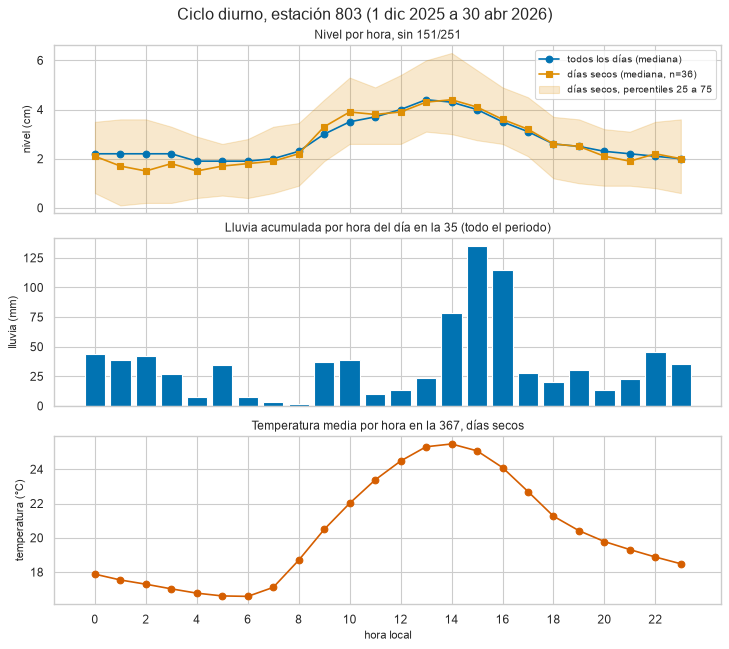

amplitud del nivel en días secos (12-16 h menos 3-7 h, calidad 1): mediana 2.0 cm, positiva en 89% de 35 días
Spearman entre días, amplitud del nivel frente a amplitud de la temperatura: 0.34 (p = 0.049)


In [15]:
fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True, constrained_layout=True)
axs[0].plot(perfil_todos.index, perfil_todos, marker="o", color=COLOR["1 o 2: confiable"], label="todos los días (mediana)")
axs[0].plot(perfil_seco.index, perfil_seco[0.5], marker="s", color=COLOR["151 o 251: dudoso"],
            label=f"días secos (mediana, n={len(dias_secos)})")
axs[0].fill_between(perfil_seco.index, perfil_seco[0.25], perfil_seco[0.75], color=COLOR["151 o 251: dudoso"], alpha=0.2,
                    label="días secos, percentiles 25 a 75")
axs[0].set(ylabel="nivel (cm)", title="Nivel por hora, sin 151/251")
axs[0].legend()
axs[1].bar(lluvia_hora.index, lluvia_hora, color=COLOR["1 o 2: confiable"])
axs[1].set(ylabel="lluvia (mm)", title="Lluvia acumulada por hora del día en la 35 (todo el periodo)")
axs[2].plot(t_hora.index, t_hora, marker="o", color=COLOR["1504: negativo"])
axs[2].set(ylabel="temperatura (°C)", xlabel="hora local", title="Temperatura media por hora en la 367, días secos",
           xticks=range(0, 24, 2))
fig.suptitle(f"Ciclo diurno, estación 803 ({PERIODO})")
plt.show()

filas = []
for dia in dias_secos:
    n_d, t_d = nivel[cal == 1].loc[dia:dia + pd.Timedelta("23h59min")], t367.loc[dia:dia + pd.Timedelta("23h59min")]
    filas.append({"dia": dia, "amp_nivel": n_d.between_time("12:00", "15:59").median() - n_d.between_time("03:00", "06:59").median(),
                  "amp_t": t_d.between_time("12:00", "15:59").mean() - t_d.between_time("03:00", "06:59").mean()})
amp = pd.DataFrame(filas).dropna()
r = spearmanr(amp["amp_nivel"], amp["amp_t"])
print(f"amplitud del nivel en días secos (12-16 h menos 3-7 h, calidad 1): mediana {amp['amp_nivel'].median():.1f} cm, "
      f"positiva en {(amp['amp_nivel'] > 0).mean():.0%} de {len(amp)} días")
print(f"Spearman entre días, amplitud del nivel frente a amplitud de la temperatura: {r.statistic:.2f} (p = {r.pvalue:.3f})")

Hay un ciclo diurno que no viene de la lluvia. En los 36 días secos la mediana va de 1,5 cm a las 2 h a 4,4 cm a las 14 h, casi igual que en todos los días. La lluvia sí se concentra en la tarde (328 de 853 mm entre las 14 y las 16 h), pero en un día seco no llueve y el ciclo sigue. La amplitud (12 a 16 h menos 3 a 7 h) es positiva en el 89 % de 35 días secos con dato, con mediana de 2,0 cm, y el máximo cae a la misma hora que el de la temperatura en la 367.

Entre días, la amplitud del nivel y la de la temperatura apenas se asocian (Spearman 0,34, p = 0,049). Las dos variables comparten el ciclo diurno, así que esto no prueba una causa. En una quebrada la evapotranspiración tendería a bajar el caudal en la tarde, no a subirlo. Hipótesis: un efecto térmico en el sensor de distancia (por ejemplo, si es ultrasónico, el aire caliente acorta la distancia medida y sube el nivel reportado) o vertimientos diurnos. Para cerrarla hace falta saber qué sensor es o comparar con una lectura de mira a las 5 h y a las 14 h en un día seco. En A5 se ve que el ciclo sigue después del cambio de ruido del 3 de marzo.

¿Hay ciclo semanal (por ejemplo, vertimientos distintos entre semana y fin de semana)?

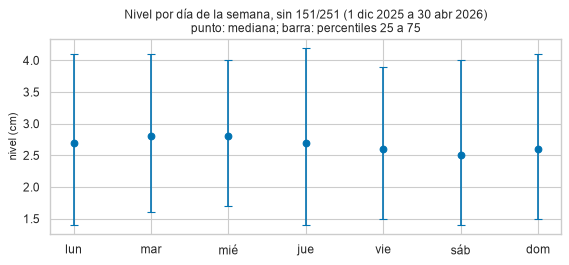

,lun,mar,mié,jue,vie,sáb,dom
todos,2.7,2.8,2.8,2.7,2.6,2.5,2.6
p25,1.4,1.6,1.7,1.4,1.5,1.4,1.5
p75,4.1,4.1,4.0,4.2,3.9,4.0,4.1


In [16]:
sem = pd.DataFrame({"todos": nivel_util.groupby(d.index.day_of_week).median(),
                    "p25": nivel_util.groupby(d.index.day_of_week).quantile(0.25),
                    "p75": nivel_util.groupby(d.index.day_of_week).quantile(0.75)})
sem.index = DIAS
fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
ax.errorbar(sem.index, sem["todos"], yerr=[sem["todos"] - sem["p25"], sem["p75"] - sem["todos"]], fmt="o",
            color=COLOR["1 o 2: confiable"], capsize=4)
ax.set(ylabel="nivel (cm)", title=f"Nivel por día de la semana, sin 151/251 ({PERIODO})\npunto: mediana; barra: percentiles 25 a 75")
plt.show()
display(sem.round(1).T)

No hay ciclo semanal: la mediana por día de la semana va de 2,5 a 2,8 cm y los rangos entre percentiles 25 y 75 se superponen casi por completo. Si hay vertimientos ligados a la semana laboral, no se notan en el nivel.

### Línea base y tendencia

El mínimo diario es sensible a un solo minuto ruidoso; el percentil 10 diario es más estable para seguir la línea base. Para no escoger fechas a ojo, se busca el par de cortes que mejor divide el percentil 10 diario en tres tramos de media constante (mínimos cuadrados, tramos de al menos 7 días). Es solo exploratorio.

In [17]:
diario = pd.DataFrame({"media": nivel_util.resample("D").mean(), "minimo": nivel_util.resample("D").min(),
                       "p10": nivel_util.resample("D").quantile(0.1), "maximo": nivel.resample("D").max(),
                       "con_meseta": meseta.resample("D").sum() > 0, "lluvia": lluvia_dia})
assert diario["p10"].notna().all()
y = diario["p10"].to_numpy()
n_d = len(y)
acum, acum2 = np.r_[0, np.cumsum(y)], np.r_[0, np.cumsum(y ** 2)]
sse = lambda a, b: acum2[b] - acum2[a] - (acum[b] - acum[a]) ** 2 / (b - a)
_, i, j = min((sse(0, i) + sse(i, j) + sse(j, n_d), i, j) for i in range(7, n_d - 14) for j in range(i + 7, n_d - 7))
cortes = [0, i, j, n_d]
tramos = pd.DataFrame([{"desde": diario.index[a].date(), "hasta": diario.index[b - 1].date(), "dias": b - a,
                        "p10_medio_cm": y[a:b].mean(), "p10_mediana_cm": np.median(y[a:b]),
                        "mediana_diaria_cm": nivel_util.loc[diario.index[a]:diario.index[b - 1] + pd.Timedelta("23h59min")].median(),
                        "lluvia_mm_dia": diario["lluvia"].iloc[a:b].mean()} for a, b in zip(cortes[:-1], cortes[1:])])
limites = [diario.index[k] for k in cortes[:-1]] + [diario.index[-1] + pd.Timedelta("1D")]
etiquetas = [f"{a.day} {MESES[a.month - 1]} a {(b - pd.Timedelta('1D')).day} {MESES[(b - pd.Timedelta('1D')).month - 1]}"
             for a, b in zip(limites[:-1], limites[1:])]
tramo = pd.Series(pd.cut(d.index, limites, right=False, labels=etiquetas), index=d.index)
tramo_dia = pd.Series(pd.cut(diario.index, limites, right=False, labels=etiquetas), index=diario.index)
display(tramos.round(2))
print("lluvia y p10 alrededor del primer corte:")
display(diario[["p10", "minimo", "lluvia"]].iloc[i - 4:i + 4].round(2))
hueco_previo = huecos[huecos["inicio"].dt.normalize() == diario.index[i - 1]]
print("huecos del día anterior al primer corte:", hueco_previo.to_dict("records"))

,desde,hasta,dias,p10_medio_cm,p10_mediana_cm,mediana_diaria_cm,lluvia_mm_dia
0,2025-12-01,2026-03-02,92,0.30,0.3,2.3,5.44
1,2026-03-03,2026-04-07,36,1.62,1.7,2.9,5.79
2,2026-04-08,2026-04-30,23,0.96,1.4,3.1,6.27


lluvia y p10 alrededor del primer corte:


,p10,minimo,lluvia
fecha_hora,,,
2026-02-27,-0.2,-0.9,0.00
2026-02-28,-0.1,-2.1,0.00
2026-03-01,-0.5,-3.4,0.00
2026-03-02,0.2,-3.1,0.00
2026-03-03,1.3,-1.3,0.00
2026-03-04,1.0,-4.1,8.64
2026-03-05,1.6,1.3,22.48
2026-03-06,1.8,1.2,0.13


huecos del día anterior al primer corte: [{'inicio': Timestamp('2026-03-02 11:59:00'), 'fin': Timestamp('2026-03-02 12:20:00'), 'minutos': 22, 'dia_semana': 'lun'}]


¿Cómo evoluciona el nivel en el periodo, hay tendencia o cambio de línea base?

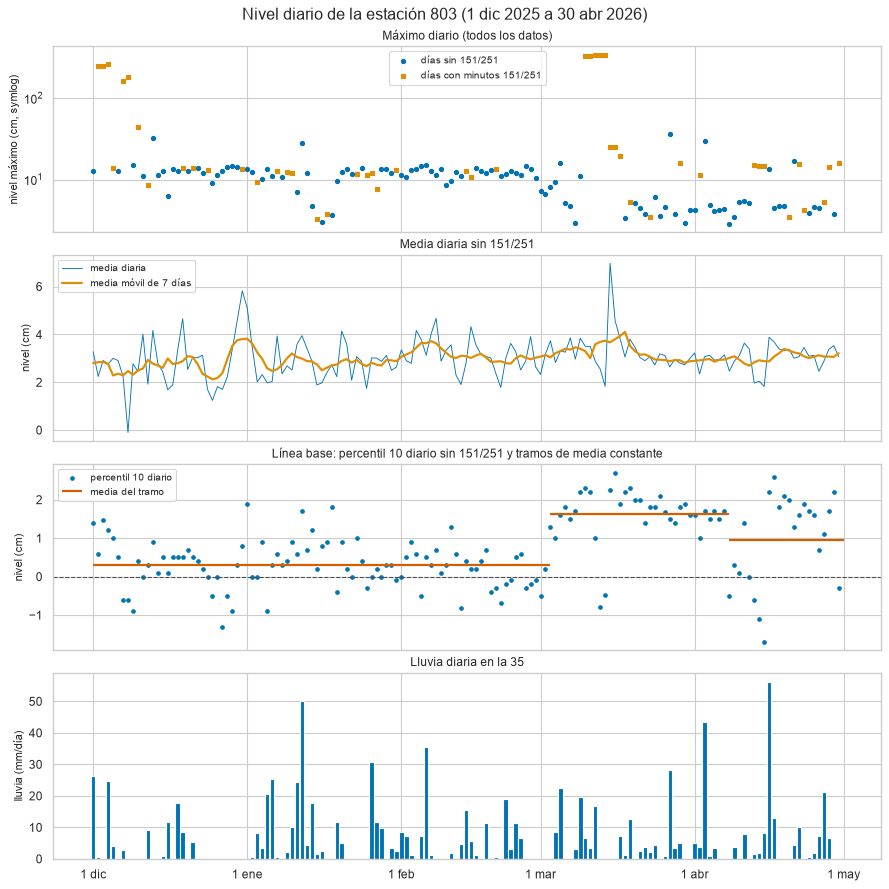

In [18]:
fig, axs = plt.subplots(4, 1, figsize=(11, 11), sharex=True, constrained_layout=True)
for con, g_ in [(False, "1 o 2: confiable"), (True, "151 o 251: dudoso")]:
    s = diario[diario["con_meseta"] == con]
    axs[0].scatter(s.index, s["maximo"], s=14, color=COLOR[g_], marker=MARCA[g_],
                   label="días con minutos 151/251" if con else "días sin 151/251")
axs[0].set_yscale("symlog", linthresh=10)
axs[0].set(ylabel="nivel máximo (cm, symlog)", title="Máximo diario (todos los datos)")
axs[0].legend(loc="upper center")
axs[1].plot(diario.index, diario["media"], lw=0.8, color=COLOR["1 o 2: confiable"], label="media diaria")
axs[1].plot(diario.index, diario["media"].rolling(7, center=True, min_periods=4).mean(), lw=2,
            color=COLOR["151 o 251: dudoso"], label="media móvil de 7 días")
axs[1].set(ylabel="nivel (cm)", title="Media diaria sin 151/251")
axs[1].legend(loc="upper left")
axs[2].scatter(diario.index, diario["p10"], s=10, color=COLOR["1 o 2: confiable"], label="percentil 10 diario")
for a, b in zip(cortes[:-1], cortes[1:]):
    axs[2].hlines(y[a:b].mean(), diario.index[a], diario.index[b - 1] + pd.Timedelta("1D"), color=COLOR["1504: negativo"], lw=2,
                  label="media del tramo" if a == 0 else None)
axs[2].axhline(0, color="0.3", lw=1, ls="--")
axs[2].set(ylabel="nivel (cm)", title="Línea base: percentil 10 diario sin 151/251 y tramos de media constante")
axs[2].legend(loc="upper left")
axs[3].bar(diario.index, diario["lluvia"], width=0.9, color=COLOR["1 o 2: confiable"])
axs[3].set(ylabel="lluvia (mm/día)", title="Lluvia diaria en la 35")
fechas(axs[3])
fig.suptitle(f"Nivel diario de la estación 803 ({PERIODO})")
guardar(fig, "resumen_periodo")
plt.show()

No hay una tendencia sostenida. El percentil 10 diario se mueve en escalones, con tres tramos: 0,30 cm del 1 dic al 2 mar, 1,62 cm del 3 mar al 7 abr y 0,96 cm del 8 al 30 abr. El escalón del 3 mar (+1,3 cm) llega después de cinco días sin lluvia (27 feb a 3 mar, 0 mm) y la lluvia media por día casi no cambia entre tramos (5,44, 5,79 y 6,27 mm/día), así que una recarga del caudal base no lo explica. El día anterior hay un hueco de 22 minutos a mediodía (2 mar, 11:59 a 12:20). Inferido: hubo una intervención en la estación (mantenimiento, cambio de sensor o de cota) que no está documentada. En A5 se ve que ese mismo día también cambió el ruido del sensor.

El máximo diario muestra las mesetas 151/251 de diciembre y marzo muy por encima de cualquier creciente real del periodo (36,2 cm). La media diaria con su media móvil de 7 días se mueve entre 2 y 4 cm casi todo el periodo.

Sobre la descomposición: una STL sobre la serie horaria obligaría a rellenar las horas de las mesetas 151/251 (más de 130 h). Aquí no aporta más que lo ya visto por separado y sin rellenar: línea base por tramos, ciclo diurno de unos centímetros y pulsos cortos de lluvia. La descomposición formal queda para la Tarea B.

## A5. Consistencia física e interna

Solo hay dos columnas, así que la consistencia interna es entre el valor y su código de calidad. La física se revisa con la velocidad de cambio del nivel, con la lluvia de la 35 y con el control de calidad propio (`siata.calidad`).

### Mesetas con código 151/251

Episodio: minutos 151/251 seguidos, uniendo interrupciones de hasta 10 minutos. Salto de entrada: nivel del primer minuto del episodio menos el último minuto válido antes; salto de salida: primer minuto válido después menos el último del episodio.

In [19]:
idx = pd.Series(d.index[meseta])
ep = idx.groupby((idx.diff() > pd.Timedelta("11min")).cumsum().to_numpy()).agg(["first", "last"]).set_axis(["inicio", "fin"], axis=1)
filas = []
for e in ep.itertuples():
    trozo = nivel.loc[e.inicio:e.fin][meseta.loc[e.inicio:e.fin]]
    antes = nivel_util.loc[:e.inicio - pd.Timedelta("1min")].dropna()
    despues = nivel_util.loc[e.fin + pd.Timedelta("1min"):].dropna()
    filas.append({"inicio": e.inicio, "fin": e.fin, "horas": round(((e.fin - e.inicio).total_seconds() / 60 + 1) / 60, 1),
                  "minutos_151_251": len(trozo),
                  "nivel_mediano": trozo.median(), "nivel_min": trozo.min(), "nivel_max": trozo.max(),
                  "salto_entrada": trozo.iloc[0] - antes.iloc[-1] if len(antes) else np.nan,
                  "salto_salida": despues.iloc[0] - trozo.iloc[-1] if len(despues) else np.nan,
                  "lluvia_3h_antes_mm": lluvia0.loc[e.inicio - pd.Timedelta("3h"):e.inicio - pd.Timedelta("1min")].sum(),
                  "lluvia_durante_mm": lluvia0.loc[e.inicio:e.fin].sum()})
episodios = pd.DataFrame(filas)
largos = episodios[episodios["horas"] >= 1]
print(f"{len(episodios)} episodios; {len(largos)} de 1 h o más, con {largos['minutos_151_251'].sum()} de los {meseta.sum()} min de 151/251")
display(largos.set_index(["inicio", "fin"]).round(1))
print(f"minutos 151/251 sin lluvia en las 3 h previas: {(lluvia_3h[meseta] < 0.1).mean():.1%} (menos de 0,1 mm), "
      f"{(lluvia_3h[meseta] < 1).mean():.1%} (menos de 1 mm)")
for a, b in [("2025-12-02", "2025-12-08"), ("2026-03-10", "2026-03-17")]:
    mm = meseta.loc[a:b]
    s = nivel.loc[a:b][mm]
    print(f"{a} a {b}: {mm.sum()} min ({mm.sum() / 60:.1f} h) con 151/251, nivel mediano {s.median()} cm "
          f"(de {s.min()} a {s.max()}), lluvia en la 35 en esos días {lluvia0.loc[a:b].sum():.1f} mm")
alto = meseta & (nivel >= 100)
print("horas del día de los minutos 151/251 de 100 cm o más en marzo:",
      (alto & (mes == pd.Period("2026-03"))).groupby(hora).sum().loc[lambda s: s > 0].to_dict())
x = cal.loc["2026-03-14 19:00":"2026-03-17 12:00"]
print("14 a 17 mar:", x.dropna().astype(int).value_counts().to_dict(), "| cambios de código entre minutos:", int((x != x.shift()).sum() - 1))
sobre_160 = nivel > 160
print(f"horas con media horaria sobre 160 cm: {int((nivel.resample('h').mean() > 160).sum())}; lluvia en la 35 "
      f"(promedio de los dos balancines) en los minutos sobre 160 cm: {lluvia0[sobre_160].sum():.1f} mm")

81 episodios; 17 de 1 h o más, con 8103 de los 8349 min de 151/251


,,horas,minutos_151_251,nivel_mediano,nivel_min,nivel_max,salto_entrada,salto_salida,lluvia_3h_antes_mm,lluvia_durante_mm
inicio,fin,,,,,,,,,
2025-12-02 18:10:00,2025-12-02 21:36:00,3.5,207,246.3,24.6,247.7,40.0,-24.8,0.5,0.0
2025-12-02 22:42:00,2025-12-03 06:14:00,7.5,453,247.0,55.9,248.6,191.5,-53.0,0.0,0.0
2025-12-03 14:43:00,2025-12-04 14:37:00,23.9,1431,244.6,45.3,263.3,42.2,-255.0,0.0,1.7
2025-12-07 00:01:00,2025-12-07 06:33:00,6.5,393,157.7,57.9,159.7,130.8,-58.4,0.0,0.0
2025-12-07 20:51:00,2025-12-08 19:20:00,22.5,1350,164.9,16.8,184.9,16.6,-101.0,0.3,0.0
2026-03-10 09:06:00,2026-03-10 10:22:00,1.3,77,329.1,3.4,336.8,173.7,0.1,0.0,0.0
2026-03-11 07:21:00,2026-03-11 10:08:00,2.8,168,329.7,71.6,334.1,322.0,-68.1,0.5,0.0
2026-03-12 07:23:00,2026-03-12 11:29:00,4.1,247,332.8,316.5,341.1,327.7,-329.6,0.0,0.0
2026-03-13 04:14:00,2026-03-13 11:22:00,7.2,429,331.4,320.7,342.3,323.2,-328.8,0.0,0.0


minutos 151/251 sin lluvia en las 3 h previas: 94.6% (menos de 0,1 mm), 97.8% (menos de 1 mm)
2025-12-02 a 2025-12-08: 3835 min (63.9 h) con 151/251, nivel mediano 235.5 cm (de 6.1 a 263.3), lluvia en la 35 en esos días 32.4 mm
2026-03-10 a 2026-03-17: 4385 min (73.1 h) con 151/251, nivel mediano 22.3 cm (de -4.4 a 344.3), lluvia en la 35 en esos días 33.9 mm
horas del día de los minutos 151/251 de 100 cm o más en marzo: {4: 46, 5: 60, 6: 73, 7: 196, 8: 240, 9: 294, 10: 209, 11: 95}
14 a 17 mar: {151: 3087, 1: 709, 1502: 105} | cambios de código entre minutos: 229
horas con media horaria sobre 160 cm: 77; lluvia en la 35 (promedio de los dos balancines) en los minutos sobre 160 cm: 1.7 mm


¿Las mesetas 151/251 son crecientes de la quebrada? Nivel minutal coloreado por código (escala symlog) y lluvia de la 35 cada 10 minutos.

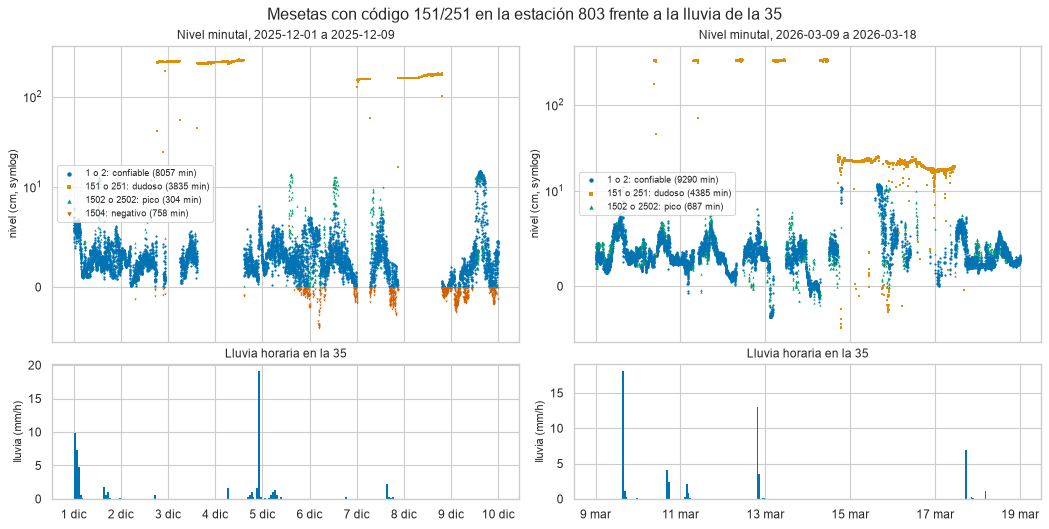

In [20]:
x = pd.DataFrame({"nivel": nivel, "grupo": grupo})
fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), sharex="col", constrained_layout=True, gridspec_kw={"height_ratios": [2.2, 1]})
for k, (a, b) in enumerate([("2025-12-01", "2025-12-09 23:59"), ("2026-03-09", "2026-03-18 23:59")]):
    puntos_por_codigo(axs[0, k], x.loc[a:b])
    axs[0, k].set_yscale("symlog", linthresh=10)
    axs[0, k].set(ylabel="nivel (cm, symlog)", title=f"Nivel minutal, {a} a {b[:10]}")
    axs[0, k].legend(loc="center left", markerscale=2, fontsize=8)
    r = lluvia0.loc[a:b].resample("h").sum()
    axs[1, k].bar(r.index, r, width=1 / 24, color=COLOR["1 o 2: confiable"], linewidth=0, align="edge")
    axs[1, k].set(ylabel="lluvia (mm/h)", title="Lluvia horaria en la 35")
    fechas(axs[1, k])
fig.suptitle("Mesetas con código 151/251 en la estación 803 frente a la lluvia de la 35")
guardar(fig, "mesetas_151")
plt.show()

Las mesetas 151/251 son una falla del sensor, no crecientes. La evidencia:

1. Duración y nivel: 8103 de los 8349 minutos están en 17 episodios de 1 h o más. Del 2 al 8 dic suman 63,9 h en torno a 245 y 160 cm; del 10 al 17 mar suman 73,1 h, primero en torno a 330 cm y luego a unos 20 cm.
2. Sin lluvia: el 94,6 % de esos minutos no tiene lluvia en las 3 h previas en la 35, a 240 m. Ningún episodio largo tiene más de 0,5 mm en las 3 h previas y solo uno tiene lluvia durante (1,7 mm en 24 h).
3. Forma: entran y salen de golpe, con saltos de hasta 331,4 cm de subida y 329,6 cm de bajada en un minuto, y al salir vuelven al nivel de antes sin curva de recesión. Una creciente real sube con la lluvia y baja de forma gradual.
4. Escala: el evento de lluvia más fuerte del periodo (43,6 mm el 3 abr) llevó el nivel a 30,3 cm. Una meseta de 330 cm sin lluvia no es física en esta quebrada.
5. Horario: del 10 al 14 mar la meseta de 330 cm se repite cada mañana entre las 4 y las 11 h, con el máximo de minutos a las 9 h. Una quebrada no crece a la misma hora cinco mañanas seguidas sin que llueva en esas horas (la 35 midió 0 mm durante los cinco episodios).
6. Dos señales a la vez: del 14 al 17 mar el código cambia 229 veces entre la meseta 151 (3087 minutos) y datos a otro nivel con 1 (709 minutos) o 1502 (105 minutos). Una sola superficie de agua no puede estar en dos niveles en minutos alternos.

Causa probable (hipótesis, no verificable con estos datos): si el sensor mide distancia (A1), algo se interpone entre el sensor y el agua, como vegetación, un objeto o condensación, o hay una falla electrónica. El episodio del 14 mar coincide con el hueco de 35 minutos.

### Control propio frente a la columna calidad

Banderas del control determinista de `siata.calidad` (1 bueno, 2 no evaluado, 3 sospechoso, 4 malo, 9 faltante) cruzadas con el código de SIATA, y qué pruebas propias se disparan sobre los minutos 151/251.

In [21]:
cruce = pd.crosstab(salida["calidad"].fillna(-1).astype(int), salida["b_nivel"])
cruce = cruce.rename(index={-1: "sin registro"}, columns={1: "bueno", 3: "sospechoso", 4: "malo", 9: "faltante"})
display(cruce)
ind = pd.read_csv(D.RAIZ / "parte2" / "resultados" / "indicadores_periodo.csv", dtype={"codigo": str}).query("codigo == '803'")
display(ind[["completitud", "validos", "kappa", "falsos_confiables", "dudosos_que_pasan"]].round(4))
fallas = pd.read_parquet(D.DIR_SALIDAS / "fallas.parquet").query("codigo == '803'")
f = fallas.assign(cal=cal.reindex(fallas["fecha_hora"]).to_numpy())
print("pruebas propias que se disparan, por código de SIATA (minutos):")
display(pd.crosstab(f["prueba"], f["cal"].fillna(-1).astype(int)))
pasan = meseta & (salida["b_nivel"] == 1)
print(f"minutos 151/251 que el control propio da por buenos: {pasan.sum()}, nivel mediano {nivel[pasan].median()} cm,",
      "por mes:", pasan.groupby(mes).sum().loc[lambda s: s > 0].to_dict())

b_nivel,bueno,2,sospechoso,malo,faltante
calidad,,,,,
sin registro,0,0,0,0,122
1,190855,170,17,0,0
2,42,0,0,0,0
151,716,0,2884,4355,0
251,0,0,1,393,0
1502,14319,0,12,2,0
1504,2984,0,3,0,0
2502,508,0,57,0,0


,completitud,validos,kappa,falsos_confiables,dudosos_que_pasan
8,0.9994,0.9637,0.4192,0.001,0.7062


pruebas propias que se disparan, por código de SIATA (minutos):


cal,-1,1,151,251,1502,1504,2502
prueba,,,,,,,
hueco,122,0,0,0,0,0,0
pico_sin_lluvia,0,0,6918,393,6,0,56
rango_clima,0,0,4648,393,0,0,0
salto,0,17,65,4,9,3,1
sin_contexto,0,170,0,0,0,0,0


minutos 151/251 que el control propio da por buenos: 716, nivel mediano 17.2 cm, por mes: {Period('2025-12', 'M'): 19, Period('2026-01', 'M'): 15, Period('2026-02', 'M'): 4, Period('2026-03', 'M'): 598, Period('2026-04', 'M'): 80}


El control propio y SIATA coinciden en lo grueso: de los 191 042 minutos con calidad 1, el control propio solo marca 17 como sospechosos y deja 170 sin evaluar, así que los falsos confiables quedan en 0,10 %. Los 170 sin evaluar (bandera 2) son los primeros minutos del periodo, el 1 dic 2025 de 00:00 a 02:49, cuando todavía no hay 3 h de lluvia previa de la 35 para la prueba espacial. El acuerdo global es moderado (kappa 0,42) porque SIATA marca como dudosos muchos minutos que pasan las reglas propias: 14 319 con 1502 y 2984 con 1504; el 70,6 % de lo dudoso pasa. Es coherente con A3: 1502 son picos de 1 a 2 cm en seco y 1504 son negativos del caudal base, que el control propio no trata como error.

En el otro sentido, 716 minutos 151/251 pasan el control propio, con nivel mediano de 17,2 cm; 598 son de marzo. Es la meseta baja del 14 al 17 mar, que queda justo bajo el umbral de 15 cm sobre la línea base de la regla pico_sin_lluvia. Propuesta para `siata.calidad`, todavía sin implementar: una regla de alternancia (el nivel salta entre dos valores muchas veces en pocas horas) o de escalón de ida y vuelta sin lluvia.

### Velocidad de cambio y ruido

Cambio entre minutos consecutivos, sin contar las entradas y salidas de las mesetas.

In [22]:
cambio = nivel.diff().where(~meseta & ~meseta.shift(fill_value=False))
sin_lluvia = lluvia_3h == 0
ruido_hora = cambio[sin_lluvia].groupby(hora[sin_lluvia]).std()
print(f"sin lluvia en 3 h: mediana de |cambio| {cambio[sin_lluvia].abs().median():.1f} cm, "
      f"p95 {cambio[sin_lluvia].abs().quantile(0.95):.1f} cm, desviación estándar {cambio[sin_lluvia].std():.2f} cm")
print(f"desviación estándar del cambio por hora: mínima {ruido_hora.min():.2f} cm a las {ruido_hora.idxmin()} h, "
      f"máxima {ruido_hora.max():.2f} cm a las {ruido_hora.idxmax()} h")
lluvia_11 = lluvia0.rolling(11, center=True, min_periods=1).sum()  # mm en los 11 minutos centrados
clase = pd.cut(lluvia_11, [-0.01, 0, 0.5, 2, 5, 100], labels=["0", "0 a 0,5", "0,5 a 2", "2 a 5", "más de 5"])
ok = cambio.notna()
tabla_cambio = pd.DataFrame({"minutos": cambio[ok].groupby(clase[ok], observed=True).size(),
                             "mediana_abs_cm": cambio[ok].abs().groupby(clase[ok], observed=True).median(),
                             "sube_mas_5cm_%": 100 * (cambio[ok] > 5).groupby(clase[ok], observed=True).mean(),
                             "baja_mas_5cm_%": 100 * (cambio[ok] < -5).groupby(clase[ok], observed=True).mean()})
tabla_cambio.index.name = "lluvia en 11 min (mm)"
display(tabla_cambio.round(2))
dias_tramo = tramo_dia.value_counts().sort_index()
por_tramo = pd.DataFrame({"ruido_sin_lluvia_cm": cambio[sin_lluvia].groupby(tramo[sin_lluvia], observed=True).std(),
                          "saltos_5cm_por_dia": (cambio.abs() > 5).groupby(tramo, observed=True).sum() / dias_tramo,
                          "max_diario_mediano_cm": nivel_util.resample("D").max().groupby(tramo_dia, observed=True).median(),
                          "p10_medio_cm": diario["p10"].groupby(tramo_dia, observed=True).mean()})
por_tramo.index.name = "tramo"
display(por_tramo.round(2))
print("cambios de más de 5 cm en un minuto:", int((cambio.abs() > 5).sum()),
      "| de ellos con lluvia de 0,5 mm o más en los 11 min centrados:", int(((cambio.abs() > 5) & (lluvia_11 >= 0.5)).sum()))

sin lluvia en 3 h: mediana de |cambio| 0.2 cm, p95 2.5 cm, desviación estándar 1.20 cm
desviación estándar del cambio por hora: mínima 0.68 cm a las 3 h, máxima 1.66 cm a las 13 h


,minutos,mediana_abs_cm,sube_mas_5cm_%,baja_mas_5cm_%
lluvia en 11 min (mm),,,,
0,199083,0.2,0.61,0.61
"0 a 0,5",5597,0.2,0.20,0.29
"0,5 a 2",2954,0.3,0.14,0.24
2 a 5,741,0.4,0.27,0.67
más de 5,412,0.7,1.70,1.21


,ruido_sin_lluvia_cm,saltos_5cm_por_dia,max_diario_mediano_cm,p10_medio_cm
tramo,,,,
1 dic a 2 mar,1.45,25.77,12.25,0.30
3 mar a 7 abr,0.44,0.67,7.30,1.62
8 abr a 30 abr,0.78,3.87,7.10,0.96


cambios de más de 5 cm en un minuto: 2484 | de ellos con lluvia de 0,5 mm o más en los 11 min centrados: 30


¿Qué tan ruidoso es el nivel minuto a minuto cuando no llueve, y cambia con la hora?

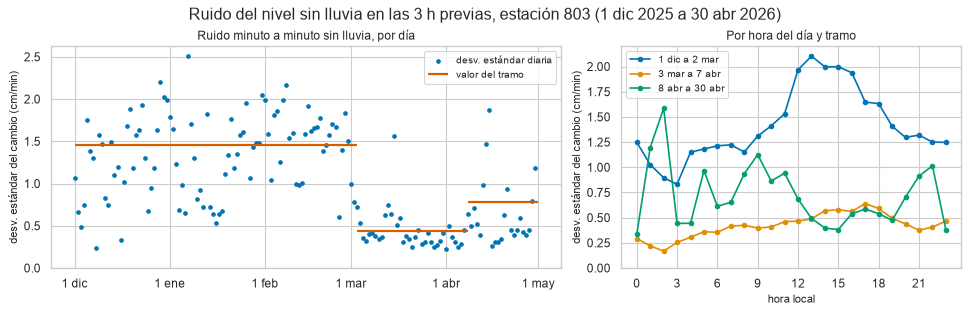

1 dic a 2 mar: ruido mínimo 0.83 cm a las 3 h, máximo 2.10 cm a las 13 h
3 mar a 7 abr: ruido mínimo 0.17 cm a las 2 h, máximo 0.64 cm a las 17 h
8 abr a 30 abr: ruido mínimo 0.33 cm a las 0 h, máximo 1.58 cm a las 2 h
amplitud diurna en días secos por tramo (cm):


,count,median
tramo,,
1 dic a 2 mar,25,2.0
3 mar a 7 abr,6,3.3
8 abr a 30 abr,4,1.8


In [23]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.5, 1]})
ruido_dia = cambio[sin_lluvia].resample("D").std()
axs[0].scatter(ruido_dia.index, ruido_dia, s=10, color=COLOR["1 o 2: confiable"], label="desv. estándar diaria")
for (a_, b_), et in zip(zip(limites[:-1], limites[1:]), etiquetas):
    axs[0].hlines(por_tramo.loc[et, "ruido_sin_lluvia_cm"], a_, b_, color=COLOR["1504: negativo"], lw=2,
                  label="valor del tramo" if et == etiquetas[0] else None)
axs[0].set(ylabel="desv. estándar del cambio (cm/min)", ylim=(0, None), title="Ruido minuto a minuto sin lluvia, por día")
axs[0].legend()
fechas(axs[0])
for et, color in zip(etiquetas, ["#0173b2", "#de8f05", "#029e73"]):
    mk = sin_lluvia & (tramo == et)
    r_h = cambio[mk].groupby(hora[mk.to_numpy()]).std()
    axs[1].plot(r_h.index, r_h, marker="o", ms=4, color=color, label=et)
axs[1].set(xlabel="hora local", ylabel="desv. estándar del cambio (cm/min)", ylim=(0, None), xticks=range(0, 24, 3),
           title="Por hora del día y tramo")
axs[1].legend()
fig.suptitle(f"Ruido del nivel sin lluvia en las 3 h previas, estación 803 ({PERIODO})")
guardar(fig, "ruido")
plt.show()
for et in etiquetas:
    mk = sin_lluvia & (tramo == et)
    r_h = cambio[mk].groupby(hora[mk.to_numpy()]).std()
    print(f"{et}: ruido mínimo {r_h.min():.2f} cm a las {r_h.idxmin()} h, máximo {r_h.max():.2f} cm a las {r_h.idxmax()} h")
amp["tramo"] = pd.cut(amp["dia"], limites, right=False, labels=etiquetas)
print("amplitud diurna en días secos por tramo (cm):")
display(amp.groupby("tramo", observed=True)["amp_nivel"].agg(["count", "median"]).round(1))

El ruido del sensor cambió dentro del periodo. Sin lluvia, la desviación estándar del cambio minuto a minuto es 1,45 cm del 1 dic al 2 mar, 0,44 cm del 3 mar al 7 abr y 0,78 cm del 8 al 30 abr; los saltos de más de 5 cm en un minuto pasan de 25,8 por día a 0,7 y luego a 3,9, y el máximo diario mediano baja de 12,25 a 7,30 cm. Los tramos son los de la línea base (A4), así que la fecha del corte no se buscó aparte para el ruido; en el gráfico por día el ruido cae en esos mismos días, entre el 1 y el 5 mar. Dos cambios en los mismos días, que empiezan sin lluvia, apuntan a una intervención en el sensor (inferido). En el primer tramo el ruido además crece hacia el mediodía: de 0,83 cm a las 3 h a 2,10 cm a las 13 h.

El ciclo diurno de A4 no es un efecto del ruido: en días secos su amplitud mediana es 2,0 cm en el primer tramo, 3,3 cm en el segundo (6 días) y 1,8 cm en el tercero (4 días).

En todo el periodo hubo 2484 saltos de más de 5 cm en un minuto y solo 30 con lluvia cerca: son ruido del sensor. Con lluvia fuerte (más de 5 mm en 11 minutos) los saltos son más frecuentes (1,70 % de subidas y 1,21 % de bajadas, frente a 0,61 % sin lluvia), pero esa clase tiene solo 412 minutos.

### Respuesta del nivel a la lluvia

Evento: minutos con lluvia en la 35 separados por menos de 60 minutos secos, con un total de 5 mm o más. Para no confundir un pico de un minuto con la creciente, el nivel se suaviza con la mediana móvil centrada de 5 minutos. Subida: máximo del nivel suavizado entre el inicio del evento y 3 h después de su fin, menos la mediana de la hora previa. Referencia ingenua: la misma medida en ventanas secas de la misma duración (sin lluvia desde 1 h antes hasta 3 h después), para saber cuánto sube el nivel sin llover.

In [24]:
suave = nivel_util.rolling(5, center=True, min_periods=3).median()
moja = lluvia0[lluvia0 > 0]
ev = (moja.groupby((moja.index.to_series().diff() > pd.Timedelta("60min")).cumsum().to_numpy())
      .agg(inicio=lambda s: s.index[0], fin=lambda s: s.index[-1], total="sum"))
ev = ev[ev["total"] >= 5].reset_index(drop=True)


def respuesta(ini, fin):
    antes = suave.loc[ini - pd.Timedelta("60min"):ini - pd.Timedelta("1min")].median()
    ventana = suave.loc[ini:fin + pd.Timedelta("3h")]
    if ventana.isna().all():
        return np.nan, np.nan, np.nan
    pico = ventana.idxmax()
    return ventana.max() - antes, (pico - ini).total_seconds() / 60, pico


filas = []
for e in ev.itertuples():
    sub, t_pico, pico = respuesta(e.inicio, e.fin)
    i10 = lluvia0.loc[e.inicio:e.fin].rolling(10, min_periods=1).sum()
    crudo_v = nivel_util.loc[e.inicio:e.fin + pd.Timedelta("3h")]
    filas.append({"inicio": e.inicio, "lluvia_mm": e.total, "duracion_min": (e.fin - e.inicio).total_seconds() / 60 + 1,
                  "max_10min_mm": i10.max(), "subida_cm": sub, "min_al_pico": t_pico,
                  "min_pico_vs_max_intensidad": (pico - i10.idxmax()).total_seconds() / 60 if pd.notna(pico) else np.nan,
                  "codigo_en_pico_crudo": cal.loc[crudo_v.idxmax()] if crudo_v.notna().any() else np.nan})
eventos = pd.DataFrame(filas)
dur = eventos["duracion_min"].median()
ventana_total = pd.Timedelta(minutes=60 + dur) + pd.Timedelta("3h")
seco_ok = lluvia0.rolling(ventana_total).sum().shift(-int(ventana_total / pd.Timedelta("1min")) + 60) == 0
candidatos = d.index[seco_ok.reindex(d.index, fill_value=False).to_numpy()]
rng = np.random.default_rng(42)
inicios = pd.DatetimeIndex(rng.choice(candidatos, 500, replace=False))
nulo = pd.Series([respuesta(t, t + pd.Timedelta(minutes=dur - 1))[0] for t in inicios], index=inicios).dropna()
p95 = nulo.quantile(0.95)
print(f"{len(eventos)} eventos de 5 mm o más; lluvia mediana {eventos['lluvia_mm'].median():.1f} mm, máxima {eventos['lluvia_mm'].max():.1f} mm")
print(f"subida en eventos: mediana {eventos['subida_cm'].median():.1f} cm, máxima {eventos['subida_cm'].max():.1f} cm")
print(f"subida en {len(nulo)} ventanas secas: mediana {nulo.median():.1f} cm, p95 {p95:.1f} cm, máxima {nulo.max():.1f} cm")
print(f"eventos con subida mayor que el p95 seco: {(eventos['subida_cm'] > p95).sum()} de {len(eventos)}")
print("Mann-Whitney eventos frente a ventanas secas: p =", f"{mannwhitneyu(eventos['subida_cm'].dropna(), nulo, alternative='greater').pvalue:.2g}")
r = spearmanr(eventos["lluvia_mm"], eventos["subida_cm"], nan_policy="omit")
r10 = spearmanr(eventos["max_10min_mm"], eventos["subida_cm"], nan_policy="omit")
print(f"Spearman lluvia total frente a subida: {r.statistic:.2f} (p = {r.pvalue:.3f}); intensidad máxima en 10 min: {r10.statistic:.2f} (p = {r10.pvalue:.3f})")
print(f"minutos del inicio de la lluvia al pico: mediana {eventos['min_al_pico'].median():.0f}; "
      f"pico frente al máximo de intensidad: mediana {eventos['min_pico_vs_max_intensidad'].median():.0f} min "
      f"(p25 {eventos['min_pico_vs_max_intensidad'].quantile(0.25):.0f}, p75 {eventos['min_pico_vs_max_intensidad'].quantile(0.75):.0f})")
print("código de SIATA en el minuto más alto de cada evento:", eventos["codigo_en_pico_crudo"].value_counts().to_dict())
display(eventos.sort_values("lluvia_mm", ascending=False).head(6).set_index("inicio").round(1))
eventos["tramo"] = pd.cut(eventos["inicio"], limites, right=False, labels=etiquetas)
nulo_tramo = pd.Series(pd.cut(nulo.index, limites, right=False, labels=etiquetas), index=nulo.index)
p95_tramo = nulo.groupby(nulo_tramo, observed=True).quantile(0.95)
print("por tramo:")
por_tramo_ev = pd.DataFrame({"eventos": eventos.groupby("tramo", observed=True).size(),
                      "subida_mediana_cm": eventos.groupby("tramo", observed=True)["subida_cm"].median(),
                      "ventanas_secas": nulo.groupby(nulo_tramo, observed=True).size(), "p95_seco_cm": p95_tramo,
                      "eventos_sobre_p95": eventos.groupby("tramo", observed=True).apply(
                          lambda g: int((g["subida_cm"] > p95_tramo[g.name]).sum()))})
display(por_tramo_ev.round(1))

47 eventos de 5 mm o más; lluvia mediana 10.2 mm, máxima 43.6 mm
subida en eventos: mediana 4.5 cm, máxima 29.5 cm
subida en 480 ventanas secas: mediana 2.8 cm, p95 10.3 cm, máxima 27.6 cm
eventos con subida mayor que el p95 seco: 3 de 47
Mann-Whitney eventos frente a ventanas secas: p = 0.00099
Spearman lluvia total frente a subida: 0.34 (p = 0.021); intensidad máxima en 10 min: 0.18 (p = 0.237)
minutos del inicio de la lluvia al pico: mediana 25; pico frente al máximo de intensidad: mediana 1 min (p25 -4, p75 18)
código de SIATA en el minuto más alto de cada evento: {1.0: 45, 1502.0: 2}


,lluvia_mm,duracion_min,max_10min_mm,subida_cm,min_al_pico,min_pico_vs_max_intensidad,codigo_en_pico_crudo
inicio,,,,,,,
2026-04-03 16:02:00,43.6,75.0,16.1,24.7,27.0,7.0,1.0
2026-01-26 22:12:00,37.0,189.0,7.9,5.9,116.0,22.0,1.0
2026-04-16 04:56:00,35.4,158.0,14.0,9.6,43.0,-3.0,1.0
2026-02-06 00:55:00,35.3,313.0,9.8,9.4,80.0,-2.0,1.0
2026-01-12 09:07:00,29.0,135.0,7.4,5.5,101.0,74.0,1.0
2026-03-27 09:53:00,27.6,97.0,16.8,29.5,22.0,4.0,1.0


por tramo:


,eventos,subida_mediana_cm,ventanas_secas,p95_seco_cm,eventos_sobre_p95
1 dic a 2 mar,29,5.3,297,11.1,1
3 mar a 7 abr,9,3.4,122,4.0,4
8 abr a 30 abr,9,3.3,61,4.0,3


¿Cuánto sube el nivel con la lluvia frente a lo que sube sin llover, y cómo se ve el evento más fuerte minuto a minuto?

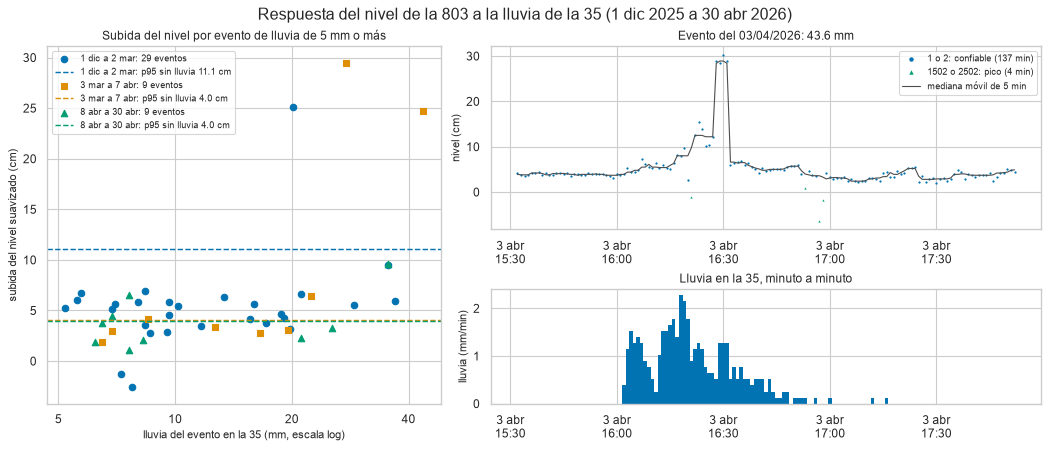

mayor caída en un minuto durante el evento: -23.1 cm a las 16:32 | lluvia en ese minuto: 0.508 mm
nivel máximo del evento: 30.3 cm; minutos por encima de 20 cm: 4


In [25]:
mayor = eventos.loc[eventos["lluvia_mm"].idxmax()]
ev_a, ev_b = mayor["inicio"] - pd.Timedelta("30min"), mayor["inicio"] + pd.Timedelta("110min")
fig = plt.figure(figsize=(13, 5.5), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.4], height_ratios=[1.6, 1])
ax = fig.add_subplot(gs[:, 0])
for et, color, marca in zip(etiquetas, ["#0173b2", "#de8f05", "#029e73"], ["o", "s", "^"]):
    g_ = eventos[eventos["tramo"] == et]
    ax.scatter(g_["lluvia_mm"], g_["subida_cm"], s=34, color=color, marker=marca, label=f"{et}: {len(g_)} eventos")
    ax.axhline(p95_tramo[et], color=color, ls="--", lw=1.3, label=f"{et}: p95 sin lluvia {p95_tramo[et]:.1f} cm")
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 40])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set(xlabel="lluvia del evento en la 35 (mm, escala log)", ylabel="subida del nivel suavizado (cm)",
       title="Subida del nivel por evento de lluvia de 5 mm o más")
ax.legend(loc="upper left", fontsize=8)
ax1 = fig.add_subplot(gs[0, 1])
x = pd.DataFrame({"nivel": nivel, "grupo": grupo}).loc[ev_a:ev_b]
puntos_por_codigo(ax1, x)
ax1.plot(suave.loc[ev_a:ev_b].index, suave.loc[ev_a:ev_b], color="0.3", lw=1, label="mediana móvil de 5 min")
ax1.set(ylabel="nivel (cm)", title=f"Evento del {mayor['inicio']:%d/%m/%Y}: {mayor['lluvia_mm']:.1f} mm")
ax1.legend(loc="upper right", fontsize=8, markerscale=2)
ax2 = fig.add_subplot(gs[1, 1], sharex=ax1)
ax2.bar(lluvia.loc[ev_a:ev_b].index, lluvia.loc[ev_a:ev_b], width=1 / 1440, color=COLOR["1 o 2: confiable"], linewidth=0)
ax2.set(ylabel="lluvia (mm/min)", title="Lluvia en la 35, minuto a minuto")
fechas(ax2, hora=True)
fig.suptitle(f"Respuesta del nivel de la 803 a la lluvia de la 35 ({PERIODO})")
guardar(fig, "respuesta_lluvia")
plt.show()
cambio_ev = cambio.loc[ev_a:ev_b]
print("mayor caída en un minuto durante el evento:", cambio_ev.min(), "cm a las", cambio_ev.idxmin().strftime("%H:%M"),
      "| lluvia en ese minuto:", lluvia.loc[cambio_ev.idxmin()], "mm")
print("nivel máximo del evento:", nivel_util.loc[ev_a:ev_b].max(), "cm; minutos por encima de 20 cm:", int((nivel_util.loc[ev_a:ev_b] > 20).sum()))

El nivel responde a la lluvia, pero poco y muy rápido. En los 47 eventos de 5 mm o más (con esta definición; otro criterio de separación da un número algo distinto) la subida mediana es 4,5 cm y la máxima 29,5 cm (27 mar). El pico llega una mediana de 25 minutos después de que empieza a llover y casi a la vez que el máximo de intensidad (mediana 1 minuto, entre -4 y 18 minutos en los percentiles 25 y 75): es una cuenca pequeña de respuesta inmediata. La lluvia total del evento explica poco la subida (Spearman 0,34, p = 0,021) y la intensidad máxima en 10 minutos menos aún (0,18, p = 0,24). En 45 de los 47 eventos el minuto más alto tiene calidad 1.

Frente a la referencia ingenua (ventanas secas de la misma duración), los eventos suben más (Mann-Whitney, p = 0,001), pero se separan poco. Antes del 3 mar, con el sensor ruidoso, el p95 sin lluvia es 11,1 cm y solo 1 de 29 eventos lo supera. Después del 3 mar el p95 baja a 4,0 cm y lo superan 7 de 18.

El evento más fuerte (3 abr, 43,6 mm en 75 minutos, hasta 16,1 mm en 10 minutos) muestra algo raro: el nivel pasa de 20 cm solo 4 minutos, con máximo de 30,3 cm, y cae 23,1 cm en un minuto (16:32) mientras sigue lloviendo (0,508 mm en ese minuto). También tiene caídas de un minuto por debajo de la línea base en plena lluvia, marcadas 1502. Mi hipótesis, sin confirmar, es que con lluvia intensa el sensor pierde la lectura (gotas, espuma o turbulencia), aunque también puede ser que el hidrograma real sea así de corto. Para decidir hace falta una cámara o una mira en un evento. Lo que sí se puede afirmar es que un umbral sobre el valor de un minuto se encendería y apagaría en minutos con un dato así.

### ¿Sirven los datos con calidad 1 para alertas?

Resumen de las magnitudes que importan para fijar un umbral de alerta con esta estación.

In [26]:
despues_dic = mes > pd.Period("2025-12")
resumen_alerta = pd.Series({
    "nivel máximo con calidad 1 (cm)": f"{nivel[cal == 1].max():.1f}",
    "nivel máximo con 151/251, falsa alarma si se ignora calidad (cm)": f"{nivel[meseta].max():.1f}",
    "eventos cuyo minuto más alto tiene calidad 1": f"{(eventos['codigo_en_pico_crudo'] == 1).sum()} de {len(eventos)}",
    "minutos negativos con calidad 1 después de diciembre": f"{int(((nivel < 0) & (cal == 1) & despues_dic).sum())}",
    "subida mediana por evento de 5 mm o más (cm)": f"{eventos['subida_cm'].median():.1f}",
    "p95 de la subida sin lluvia (cm)": f"{p95:.1f}",
    "amplitud diurna mediana en días secos (cm)": f"{amp['amp_nivel'].median():.1f}",
    "escalón de la línea base del primer corte (cm)": f"{tramos['p10_medio_cm'].iloc[1] - tramos['p10_medio_cm'].iloc[0]:.1f}",
    "ruido sin lluvia por tramo, desv. estándar del cambio por minuto (cm)":
        ", ".join(f"{v:.2f}" for v in por_tramo["ruido_sin_lluvia_cm"]),
    "minutos con calidad 1 que el control propio no da por buenos": f"{int(((cal == 1) & (salida['b_nivel'] != 1)).sum())}",
})
display(resumen_alerta.to_frame("valor"))

,valor
nivel máximo con calidad 1 (cm),36.2
"nivel máximo con 151/251, falsa alarma si se ignora calidad (cm)",344.3
eventos cuyo minuto más alto tiene calidad 1,45 de 47
minutos negativos con calidad 1 después de diciembre,7325
subida mediana por evento de 5 mm o más (cm),4.5
p95 de la subida sin lluvia (cm),10.3
amplitud diurna mediana en días secos (cm),2.0
escalón de la línea base del primer corte (cm),1.3
"ruido sin lluvia por tramo, desv. estándar del cambio por minuto (cm)","1.45, 0.44, 0.78"
minutos con calidad 1 que el control propio no da por buenos,187


Para alertas, calidad 1 cumple lo más importante: deja fuera las mesetas falsas (hasta 344,3 cm, que serían falsas alarmas) y conserva los picos reales (45 de 47 eventos tienen calidad 1 en su minuto más alto y el máximo con 1 es 36,2 cm). Pero calidad 1 no quiere decir que el dato esté listo para un umbral: incluye 7325 negativos después de diciembre, un ciclo diurno de 2,0 cm en seco, un escalón de 1,3 cm en la línea base y un ruido de 1,45 cm por minuto antes del 3 mar. Frente a una subida mediana de 4,5 cm por evento, ninguno de esos efectos es menor. Recomendación: umbrales sobre el nivel suavizado (mediana de 5 minutos) y relativos a la línea base del día, no sobre el valor absoluto, y confirmación con la lluvia de la 35.

## A6. Hallazgos priorizados

Las cifras de la tabla salen de las variables calculadas arriba.

In [27]:
h_meseta = meseta.sum() / 60
hallazgos = pd.DataFrame([
    {"prioridad": 1, "problema": "Mesetas falsas de nivel con código 151/251",
     "evidencia": f"{meseta.sum()} min ({h_meseta:.0f} h) entre {nivel[meseta].quantile(0.05):.0f} y {nivel[meseta].max():.0f} cm; "
                  f"{(lluvia_3h[meseta] < 0.1).mean():.0%} sin lluvia en 3 h; saltos de hasta {largos['salto_entrada'].max():.0f} cm en 1 min; "
                  f"el evento de {eventos['lluvia_mm'].max():.1f} mm solo llegó a {nivel_util.loc[ev_a:ev_b].max():.1f} cm",
     "impacto": "Falsa alarma de creciente si se ignora la columna calidad; baja la completitud útil",
     "recomendación": "Excluir 151/251 de alertas y modelos; regla de salto de ida y vuelta; avisar a mantenimiento cuando aparezcan"},
    {"prioridad": 2, "problema": "La señal de creciente apenas se separa del ruido",
     "evidencia": f"subida mediana {eventos['subida_cm'].median():.1f} cm con 5 mm o más; superan el p95 seco de su tramo "
                  f"{por_tramo_ev['eventos_sobre_p95'].iloc[0]} de {por_tramo_ev['eventos'].iloc[0]} eventos antes del 3 mar "
                  f"(p95 {por_tramo_ev['p95_seco_cm'].iloc[0]:.1f} cm) y {por_tramo_ev['eventos_sobre_p95'].iloc[1:].sum()} de "
                  f"{por_tramo_ev['eventos'].iloc[1:].sum()} después (p95 {por_tramo_ev['p95_seco_cm'].iloc[1]:.1f} cm)",
     "impacto": "Con el ruido de dic a feb un umbral fijo de nivel no distingue la mayoría de crecientes; después mejora",
     "recomendación": "Validar con mira o cámara en un evento; suavizar (mediana de 5 min) y combinar con lluvia antes de alertar"},
    {"prioridad": 3, "problema": "Cero no documentado y cambio del sensor sin registrar el 3 de marzo",
     "evidencia": f"{(nivel < 0).mean():.1%} de niveles negativos; desde el {tramos['desde'].iloc[1]} el p10 diario pasa de "
                  f"{tramos['p10_medio_cm'].iloc[0]:.1f} a {tramos['p10_medio_cm'].iloc[1]:.1f} cm y el ruido de "
                  f"{por_tramo['ruido_sin_lluvia_cm'].iloc[0]:.2f} a {por_tramo['ruido_sin_lluvia_cm'].iloc[1]:.2f} cm/min, "
                  f"tras días secos y un hueco de {hueco_previo['minutos'].sum()} min el día anterior",
     "impacto": "Los umbrales en cm no son comparables antes y después; un negativo parece error y no lo es",
     "recomendación": "Documentar la cota del cero y cada intervención en los metadatos (WIGOS); nivelación topográfica"},
    {"prioridad": 4, "problema": "El algoritmo de calidad cambió dentro del periodo",
     "evidencia": f"1504 solo en diciembre ({(cal == 1504).sum()} min); después hay {int(((nivel < 0) & (cal == 1) & despues_dic).sum())} "
                  f"negativos con 1; 2502 y 251 casi solo en diciembre; kappa con el control propio {ind['kappa'].iloc[0]:.2f}",
     "impacto": "Un mismo dato recibe códigos distintos según la fecha; las estadísticas por código no son comparables",
     "recomendación": "Versionar el algoritmo de calidad, publicar el diccionario de códigos y reprocesar el histórico"},
    {"prioridad": 5, "problema": "Ciclo diurno del nivel en días secos",
     "evidencia": f"amplitud mediana {amp['amp_nivel'].median():.1f} cm en {len(amp)} días secos, máximo a las "
                  f"{perfil_seco[0.5].idxmax()} h; Spearman con la amplitud de temperatura {spearmanr(amp['amp_nivel'], amp['amp_t']).statistic:.2f}",
     "impacto": "Sesga umbrales y modelos si se toma como caudal; el origen no está confirmado",
     "recomendación": "Hipótesis: efecto térmico del sensor o vertimientos; confirmar tipo de sensor y compensación con SIATA"},
    {"prioridad": 6, "problema": "Picos de un minuto en tiempo seco (código 1502)",
     "evidencia": f"{int((cambio.abs() > 5).sum())} cambios de más de 5 cm en 1 min, casi todos sin lluvia; desvío mediano "
                  f"{codigos.loc[1502, 'desvio_mediano_cm']:.1f} cm con 1502 frente a {codigos.loc[1, 'desvio_mediano_cm']:.1f} con 1",
     "impacto": "Ruido que dispara alertas de un minuto",
     "recomendación": "Filtro de mediana corta antes de comparar con umbrales; conservar el crudo"},
    {"prioridad": 7, "problema": "Artefacto float32 en el valor",
     "evidencia": f"residuo de hasta {residuo.max():.1e} cm frente a 0,1 cm; una resta en float32 desde una cota de unos 6 m lo reproduce exacto",
     "impacto": "Bajo: confunde al usuario y a las pruebas de igualdad o persistencia",
     "recomendación": "Redondear a 0,1 cm al ingerir y publicar la resolución"},
    {"prioridad": 8, "problema": "Huecos cortos",
     "evidencia": f"{int(falta.sum())} min en {len(huecos)} huecos, el mayor de {huecos['minutos'].max()} min; "
                  f"{int(por_hora.loc[11:13, 'sin_registro'].sum())} min entre las 11 y las 13 h",
     "impacto": "Bajo para la completitud; útil para rastrear visitas o fallas de transmisión",
     "recomendación": "Registrar las visitas de mantenimiento en los metadatos de la estación"},
])
display(hallazgos.set_index("prioridad"))

,problema,evidencia,impacto,recomendación
prioridad,,,,
1,Mesetas falsas de nivel con código 151/251,8349 min (139 h) entre 17 y 344 cm; 95% sin lluvia en 3 h; saltos de hasta 331 cm en 1 min; el evento de 43.6 mm solo llegó a 30.3 cm,Falsa alarma de creciente si se ignora la columna calidad; baja la completitud útil,Excluir 151/251 de alertas y modelos; regla de salto de ida y vuelta; avisar a mantenimiento cuando aparezcan
2,La señal de creciente apenas se separa del ruido,subida mediana 4.5 cm con 5 mm o más; superan el p95 seco de su tramo 1 de 29 eventos antes del 3 mar (p95 11.1 cm) y 7 de 18 después (p95 4.0 cm),Con el ruido de dic a feb un umbral fijo de nivel no distingue la mayoría de crecientes; después mejora,Validar con mira o cámara en un evento; suavizar (mediana de 5 min) y combinar con lluvia antes de alertar
3,Cero no documentado y cambio del sensor sin registrar el 3 de marzo,"5.4% de niveles negativos; desde el 2026-03-03 el p10 diario pasa de 0.3 a 1.6 cm y el ruido de 1.45 a 0.44 cm/min, tras días secos y un hueco de 22 min el día anterior",Los umbrales en cm no son comparables antes y después; un negativo parece error y no lo es,Documentar la cota del cero y cada intervención en los metadatos (WIGOS); nivelación topográfica
4,El algoritmo de calidad cambió dentro del periodo,1504 solo en diciembre (2987 min); después hay 7325 negativos con 1; 2502 y 251 casi solo en diciembre; kappa con el control propio 0.42,Un mismo dato recibe códigos distintos según la fecha; las estadísticas por código no son comparables,"Versionar el algoritmo de calidad, publicar el diccionario de códigos y reprocesar el histórico"
5,Ciclo diurno del nivel en días secos,"amplitud mediana 2.0 cm en 35 días secos, máximo a las 14 h; Spearman con la amplitud de temperatura 0.34",Sesga umbrales y modelos si se toma como caudal; el origen no está confirmado,Hipótesis: efecto térmico del sensor o vertimientos; confirmar tipo de sensor y compensación con SIATA
6,Picos de un minuto en tiempo seco (código 1502),"2484 cambios de más de 5 cm en 1 min, casi todos sin lluvia; desvío mediano 1.2 cm con 1502 frente a 0.2 con 1",Ruido que dispara alertas de un minuto,Filtro de mediana corta antes de comparar con umbrales; conservar el crudo
7,Artefacto float32 en el valor,"residuo de hasta 2.4e-05 cm frente a 0,1 cm; una resta en float32 desde una cota de unos 6 m lo reproduce exacto",Bajo: confunde al usuario y a las pruebas de igualdad o persistencia,"Redondear a 0,1 cm al ingerir y publicar la resolución"
8,Huecos cortos,"122 min en 20 huecos, el mayor de 35 min; 76 min entre las 11 y las 13 h",Bajo para la completitud; útil para rastrear visitas o fallas de transmisión,Registrar las visitas de mantenimiento en los metadatos de la estación


Orden de prioridad: primero lo que causa falsas alarmas o alertas perdidas (1 y 2), luego lo que hace que los datos no sean comparables en el tiempo (3 y 4) y al final lo que afecta modelos o la presentación del dato (5 a 8).